# APRAU 2026/27 — Trabalho 1
## Parte 1: Análise Exploratória de Dados (EDA)

**Dataset:** `dataset_grupo_22.csv` - 2000 perfis de pacientes, 33 *features* e 2 variáveis alvo.

### Objetivo

1. **Estatística descritiva**: qualidade dos dados, tipos, medidas de tendência central e dispersão.
2. **Análise univariada**: distribuição de cada feature e das duas variáveis alvo.
3. **Análise bivariada**: correlação entre features e relação de cada feature com `target_regression` (regressão) e `target_class` (classificação).
4. **Identificar features pouco informativas, constantes ou redundantes**, com justificação.

## 0. Dicionário de variáveis

**Demográficas e socioeconómicas**

| Variável | Definição no enunciado |
|---|---|
| `age` | Idade cronológica do paciente, em anos |
| `age_normalized` | Escalamento min-max padronizado da idade |
| `age_level` | Categoria de idade derivada (Young, Middle, Mature, Senior) |
| `gender` | Sexo biológico (Male, Female) |
| `education_level` | Escolaridade mais elevada (Primary, Secondary, Tertiary) |
| `employment_status` | Situação profissional atual (Employed, Unemployed, Retired) |

**Antropométricas**

| Variável | Definição no enunciado |
|---|---|
| `bmi` | Índice de Massa Corporal, em kg/m² |
| `bmi_level` | Estado nutricional padronizado pela OMS (Underweight, Normal, Overweight, Obese) |

**Estilo de vida**

| Variável | Definição no enunciado |
|---|---|
| `smoking` | Estado de consumo de tabaco (Never, Former, Current) |
| `physical_activity` | Intensidade de exercício semanal auto-reportada (Low, Moderate, High) |
| `stress_level` | Nível de stress psicológico quantificado (Low, Medium, High) |
| `sleep_hours` | Duração média diária de sono auto-reportada |
| `alcohol_intake` | Métrica de consumo habitual de álcool |
| `salt_intake` | Estimativa de ingestão de sódio e sal na dieta |
| `sugar_consumption` | Frequência de ingestão de açúcar refinado (Low, Medium, High) |
| `family_history` | Predisposição familiar a doenças cardiometabólicas crónicas (Yes, No) |

**Sinais vitais e hemodinâmica**

| Variável | Definição no enunciado |
|---|---|
| `systolic_bp` | Pressão arterial sistólica, em mmHg |
| `diastolic_bp` | Pressão arterial diastólica, em mmHg |
| `blood_pressure` | Medição agregada de tensão arterial |
| `heart_rate` | Frequência cardíaca em repouso, em bpm |
| `systolic_index` | Índice secundário de dinâmica de pressão hemodinâmica |

**Biomarcadores laboratoriais**

| Variável | Definição no enunciado |
|---|---|
| `HbA1c_level` | Percentagem de hemoglobina glicada (controlo glicémico a médio prazo) |
| `cholesterol` | Colesterol total sérico |
| `triglycerides` | Nível sérico de triglicéridos |
| `hdl` | Lipoproteína de alta densidade (colesterol "bom") |
| `ldl` | Lipoproteína de baixa densidade (colesterol "mau") |
| `low_hdl_cholesterol` | Indicador binário de HDL sub-ótimo |
| `high_ldl_cholesterol` | Indicador binário de risco de LDL elevado |
| `crp_level` | Proteína C-Reativa sérica (marcador de inflamação vascular sistémica) |
| `homocysteine_level` | Homocisteína plasmática (indicador de risco vascular e metabólico) |
| `calcium_baseline` | Registo de linha de base de eletrólito bioquímico |
| `plasma_value` | Indicador de variância da viscosidade plasmática |
| `ldl_alternative` | Representação alternativa do perfil de partículas lipídicas |

## 1. Estatística descritiva

### 1.1 Carregamento dos dados e preparação do ambiente

Começamos por carregar o dataset e fixar o ambiente de execução. Fixamos a semente aleatória em **42**
para que todos os resultados que envolvem aleatoriedade sejam reprodutíveis. O caminho do ficheiro é procurado tanto
na raiz do projeto como na pasta `notebooks`, para o notebook funcionar a partir de qualquer uma delas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42

dataset_name = 'dataset_grupo_22.csv'
dataset_candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f'Nao foi encontrado {dataset_name}. Execute o notebook a partir da raiz do projeto '
        'ou da pasta notebooks.'
    )

df = pd.read_csv(dataset_path)
print('Dimensao do dataset:', df.shape)
df.head()

Dimensao do dataset: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Female,Normal,Never,87,0.977,23.600,7.080,176.000,6.500,165.000,High,No,Medium,No,No,146.239,Low,7.897,12.253,113.000,104.000,24.600,14.300,89.000,72.000,92.000,Tertiary,Retired,113.000,9.420,1.415,166.000,90.000,DI_HY
1,Mature,Female,Obese,Never,56,0.621,36.700,8.200,225.756,6.859,254.443,High,No,High,Yes,Yes,149.058,Low,7.313,11.922,133.613,89.786,14.889,8.461,74.660,64.331,127.944,Tertiary,Unemployed,133.613,9.420,0.953,188.000,220.000,DI_HY
2,Mature,Male,Obese,Current,67,0.747,39.800,6.862,290.000,6.300,144.000,High,Yes,Low,No,Yes,148.563,Low,7.561,12.723,119.000,106.000,17.100,7.700,54.000,81.000,161.000,Tertiary,Employed,119.000,9.420,1.077,71.000,172.000,DI_HY
3,Middle,Female,Normal,Current,39,0.425,21.400,6.900,159.000,9.800,193.000,Low,No,Low,Yes,No,150.420,Medium,7.440,12.269,123.000,106.000,2.700,6.400,96.000,35.000,120.000,Secondary,Employed,123.000,9.420,1.579,185.000,92.000,DI_HY
4,Senior,Female,Normal,Never,74,0.828,23.000,7.080,163.000,6.500,88.000,High,No,Low,No,Yes,146.239,Low,7.897,12.253,133.000,96.000,6.400,7.000,99.000,45.000,172.000,Secondary,Retired,133.000,9.420,0.965,131.338,152.000,DI_HY


**Conclusões:** O dataset tem **2000 linhas e 35 colunas** (33 *features* e as 2 variáveis alvo), o que
corresponde ao subconjunto de 2000 registos descrito no enunciado. As primeiras linhas mostram desde já
uma mistura de valores inteiros, decimais e categorias em texto.

### 1.2 Estrutura, tipos de dados e qualidade

Antes de qualquer análise estatística é preciso saber **com que tipo de dados estamos a lidar** e se os
dados estão em condições de ser analisados. Separamos as *features* numéricas das categóricas, porque exigem técnicas descritivas diferentes.

In [2]:
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

num_cols = [c for c in df.select_dtypes(include='number').columns if c != TARGET_REG]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

print(f'Features numericas ({len(num_cols)}): {num_cols}\n')
print(f'Features categoricas ({len(cat_cols)}): {cat_cols}\n')
print('Valores em falta (total):', df.isna().sum().sum())
print('Linhas duplicadas:', df.duplicated().sum())

pd.DataFrame({'dtype': df.dtypes.astype(str),
              'n_unique': df.nunique(),
              'missing': df.isna().sum()})

Features numericas (21): ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative']

Features categoricas (12): ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']

Valores em falta (total): 0
Linhas duplicadas: 0


,dtype,n_unique,missing
age_level,object,4,0
gender,object,2,0
bmi_level,object,4,0
smoking,object,3,0
age,int64,72,0
age_normalized,float64,131,0
bmi,float64,487,0
HbA1c_level,float64,110,0
cholesterol,float64,211,0
sleep_hours,float64,217,0


**Conclusões:** Há **21 *features* numéricas** e **12 categóricas**, mais as duas variáveis alvo.

Não existem **valores em falta** nem **linhas duplicadas**, pelo que não será necessário imputar valores
nem remover registos.

As *features* categóricas estão guardadas como texto e terão de ser **codificadas** (ordinal ou one-hot)
antes de qualquer modelação, porque tanto a regressão linear como a regressão logística e a LDA operam
sobre matrizes numéricas.

### 1.3 Features numéricas

Para as variáveis numéricas calculamos as medidas habituais de tendência central (média, mediana) e de
dispersão (desvio-padrão, quartis, mínimo e máximo).

O número de valores distintos serve para detetar variáveis constantes ou quase constantes.

In [3]:
desc = df[num_cols + [TARGET_REG]].describe().T
desc['cv'] = desc['std'] / desc['mean']
desc['skew'] = df[num_cols + [TARGET_REG]].skew()
desc['kurtosis'] = df[num_cols + [TARGET_REG]].kurt()
desc['n_unique'] = df[num_cols + [TARGET_REG]].nunique()
desc

,count,mean,std,min,25%,50%,75%,max,cv,skew,kurtosis,n_unique
age,2000.000,55.191,20.286,18.000,38.000,57.000,73.000,89.000,0.368,-0.160,-1.146,72
age_normalized,2000.000,0.611,0.233,0.184,0.414,0.632,0.816,1.000,0.381,-0.160,-1.146,131
bmi,2000.000,27.807,7.180,15.000,21.800,27.535,33.700,59.450,0.258,0.107,-0.701,487
HbA1c_level,2000.000,6.846,0.573,3.500,6.817,6.943,7.011,9.000,0.084,-1.416,9.654,110
cholesterol,2000.000,225.051,41.294,150.000,191.000,225.373,258.000,299.000,0.183,-0.011,-1.017,211
sleep_hours,2000.000,7.047,1.631,4.000,5.700,7.012,8.400,10.000,0.231,-0.014,-1.011,217
triglycerides,2000.000,158.239,65.382,50.000,104.000,151.000,209.000,399.000,0.413,0.436,0.021,310
blood_pressure,2000.000,150.145,5.221,120.000,149.058,149.974,151.266,180.000,0.035,-0.584,14.173,140
crp_level,2000.000,7.375,1.100,0.011,7.277,7.458,7.706,14.615,0.149,-0.306,14.981,191
homocysteine_level,2000.000,12.379,1.123,5.110,12.253,12.417,12.621,19.874,0.091,-0.683,19.018,191


**Conclusões.**

- **`calcium_baseline` é uma *feature* constante**, com desvio-padrão exatamente 0, coeficiente de variação 0
  e **um único valor distinto** (9.42) nas 2000 linhas. Uma variável que não varia não pode explicar a
  variação de nada.
- **Há indícios de redundância.** `systolic_bp` e `systolic_index` têm estatísticas descritivas
  exatamente iguais. O mesmo acontece entre `ldl` e `ldl_alternative`, e entre `age` e
  `age_normalized` (que, pela definição do enunciado, é uma reescala da idade). Vamos confirmar na análise bivariada se são **redundantes**.
- `HbA1c_level`, `blood_pressure`, `crp_level` e `homocysteine_level` têm um IQR muito estreito face ao intervalo total (por exemplo `blood_pressure`: IQR ≈ 149–151, intervalo 120–180). Isto indica distribuições muito concentradas, com caudas longas e curtose alta.
- **As escalas são muito heterogéneas**, desde valores na ordem de 1 em `plasma_value` até cerca de 400
  em `triglycerides`. Métodos baseados em regularização (Ridge e Lasso) penalizam a magnitude dos coeficientes e são, por isso, **sensíveis à escala**, sendo
  necessário **normalizar** as *features* antes de os aplicar.

### 1.4 Features categóricas

Para as variáveis categóricas as medidas de tendência central não se aplicam. O que interessa saber é
**quantas categorias distintas existem**, qual é a mais frequente e **como se repartem os registos** por
cada categoria. Esta última informação é decisiva, visto que, categorias raras tornam-se
problemáticas na codificação e na reamostragem estratificada, e é aqui que ficamos a saber se a variável
alvo da classificação está equilibrada.

In [4]:
cat_summary = pd.DataFrame({
    'n_categorias': df[cat_cols + [TARGET_CLS]].nunique(),
    'moda': df[cat_cols + [TARGET_CLS]].mode().iloc[0],
    'freq_moda_%': [df[c].value_counts(normalize=True).iloc[0] * 100
                    for c in cat_cols + [TARGET_CLS]],
})
cat_summary

,n_categorias,moda,freq_moda_%
age_level,4,Senior,33.000
gender,2,Male,51.350
bmi_level,4,Obese,40.200
smoking,3,Never,35.650
physical_activity,3,Moderate,34.150
family_history,2,No,51.700
stress_level,3,High,35.350
low_hdl_cholesterol,2,No,82.350
high_ldl_cholesterol,2,Yes,51.100
sugar_consumption,3,Low,36.850


In [5]:
ORDENS = {
    'age_level': ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level': ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking': ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level': ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level': ['Primary', 'Secondary', 'Tertiary'],
}

def ordem_de(c):
    return ORDENS.get(c, df[c].value_counts().index.tolist())

linhas = []
for c in cat_cols + [TARGET_CLS]:
    vc = df[c].value_counts().reindex(ordem_de(c))
    for categoria, n in vc.items():
        linhas.append({'variável': c, 'categoria': str(categoria), 'n': int(n),
                       '% do total': n / len(df) * 100, 'proporção': n / len(df) * 100})

distribuicao = pd.DataFrame(linhas).set_index(['variável', 'categoria'])

variaveis = distribuicao.index.get_level_values('variável').to_series()
inicios = [k + 1 for k, muda in enumerate(variaveis.ne(variaveis.shift()).values) if muda]
estilos = [{'selector': '', 'props': 'border-collapse: collapse;'},
           {'selector': 'caption', 'props': 'font-weight: 600; padding-bottom: 8px;'},
           {'selector': 'th, td', 'props': 'padding: 3px 10px;'}]
estilos += [{'selector': f'tbody tr:nth-child({k}) th, tbody tr:nth-child({k}) td',
             'props': 'border-top: 2px solid #8a94a6;'} for k in inicios[1:]]

(distribuicao.style
    .format({'n': '{:,.0f}', '% do total': '{:.2f}%', 'proporção': lambda v: ''})
    .bar(subset=['proporção'], color='#a8c8e8', vmin=0, vmax=100)
    .set_table_styles(estilos)
    .set_properties(subset=['proporção'], **{'width': '180px'})
    .set_properties(**{'font-size': '11px'})
    .set_caption('Distribuição das categorias em cada variável categórica (n = 2000)'))

**Conclusões:** Todas as variáveis categóricas têm entre 2 e 4 categorias e nenhuma tem cardinalidade
elevada, pelo que a codificação one-hot não fará explodir o número de colunas.

A tabela mostra que **quase todas as variáveis estão praticamente equilibradas**, com as categorias a
repartir os 2000 registos em proporções semelhantes.

Apenas três variáveis fogem a esse padrão: 
- `low_hdl_cholesterol` (82.35% `No`) 
- `bmi_level` (40.20%`Obese` contra 12.20% `Underweight`) 
- `age_level` (apenas 7.25% `Young`, contra 33.00% `Senior`).

Nenhuma delas tem, ainda assim, categorias tão raras que comprometam a estratificação na fase de
modelação.

**`target_class` é a única cuja repartição é desequilibrada**: 1798 registos `DI_HY` (89.90%), contra 117 `HT` (5.85%) e apenas 85
`DI_HT` (4.25%). Este desequilíbrio condiciona todas as decisões da fase de classificação e é analisado em detalhe na secção seguinte.

## 2. Análise univariada

### 2.1 Variáveis alvo

Começamos a análise univariada pelas duas variáveis alvo, porque são elas que condicionam todas as
decisões metodológicas que se seguem.

Para `target_class` interessa a **distribuição das classes**, se estiver desequilibrada, a *accuracy*
deixa de ser uma métrica fiável e a estratificação passa a ser obrigatória nos métodos de reamostragem. Para `target_regression` interessa a **forma da distribuição**, o histograma mostra-nos a forma
geral e o gráfico Q-Q compara-a com uma distribuição normal.

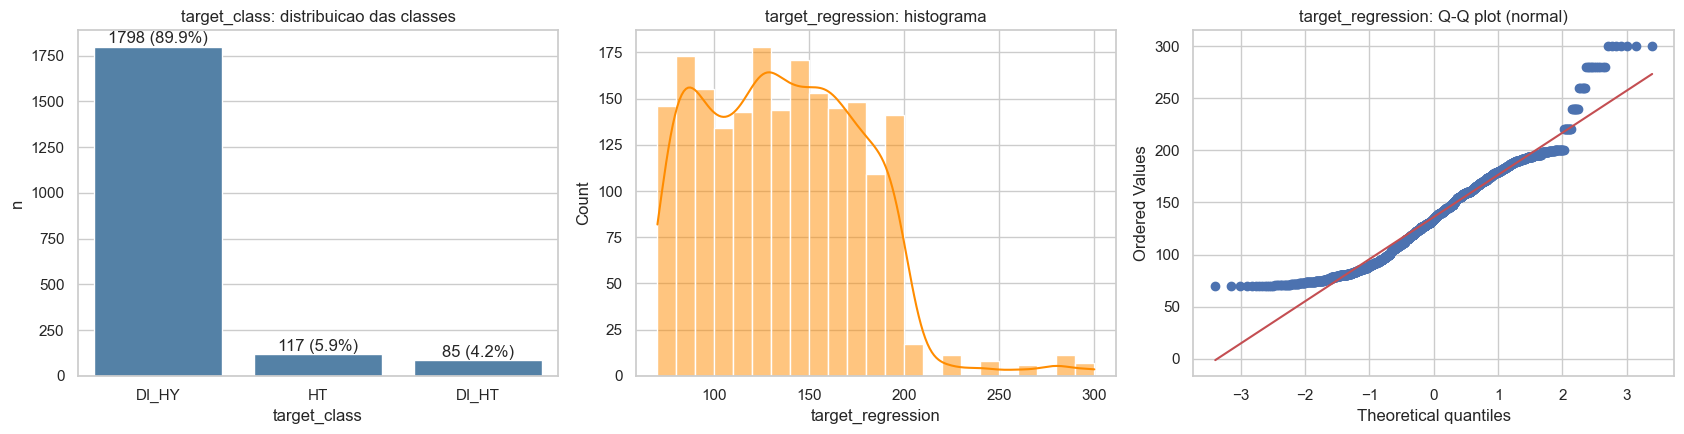

Racio de desequilibrio (maioritaria / minoritaria): 21.2
target_regression -> skew = 0.52, kurtosis = 0.42


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = df[TARGET_CLS].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], color='steelblue')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f'{v} ({v/len(df):.1%})', ha='center')
axes[0].set_title('target_class: distribuicao das classes'); axes[0].set_ylabel('n')

sns.histplot(df[TARGET_REG], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('target_regression: histograma')

stats.probplot(df[TARGET_REG], dist='norm', plot=axes[2])
axes[2].set_title('target_regression: Q-Q plot (normal)')
plt.tight_layout(); plt.show()

print(f'Racio de desequilibrio (maioritaria / minoritaria): {counts.max() / counts.min():.1f}')
print(f'target_regression -> skew = {df[TARGET_REG].skew():.2f}, '
      f'kurtosis = {df[TARGET_REG].kurt():.2f}')

**Conclusões:**

- **`target_class` está muito desequilibrada**: `DI_HY` representa cerca de 90% dos registos, contra cerca de 6% de `HT` e 4% de `DI_HT`.
  Um classificador que preveja sempre `DI_HY` já teria cerca de 90% de *accuracy*. Por isso, na classificação devemos usar métricas como **F1 macro, *balanced accuracy*, recall por classe e matriz de confusão**, com **estratificação** nos métodos de reamostragem e, eventualmente, `class_weight='balanced'`.
- **`target_regression`** varia entre 70 e 300 e tem uma ligeira assimetria positiva (cauda à direita).

### 2.2 Features numéricas: histogramas e boxplots

Os **histogramas** mostram a forma de cada distribuição, se é simétrica ou assimétrica, se tem um ou
vários picos, e se é aproximadamente uniforme ou concentrada. Os ***boxplots*** mostram a mesma
informação sob outro ângulo, mediana, quartis e valores afastados, e permitem comparar a dispersão
entre variáveis.

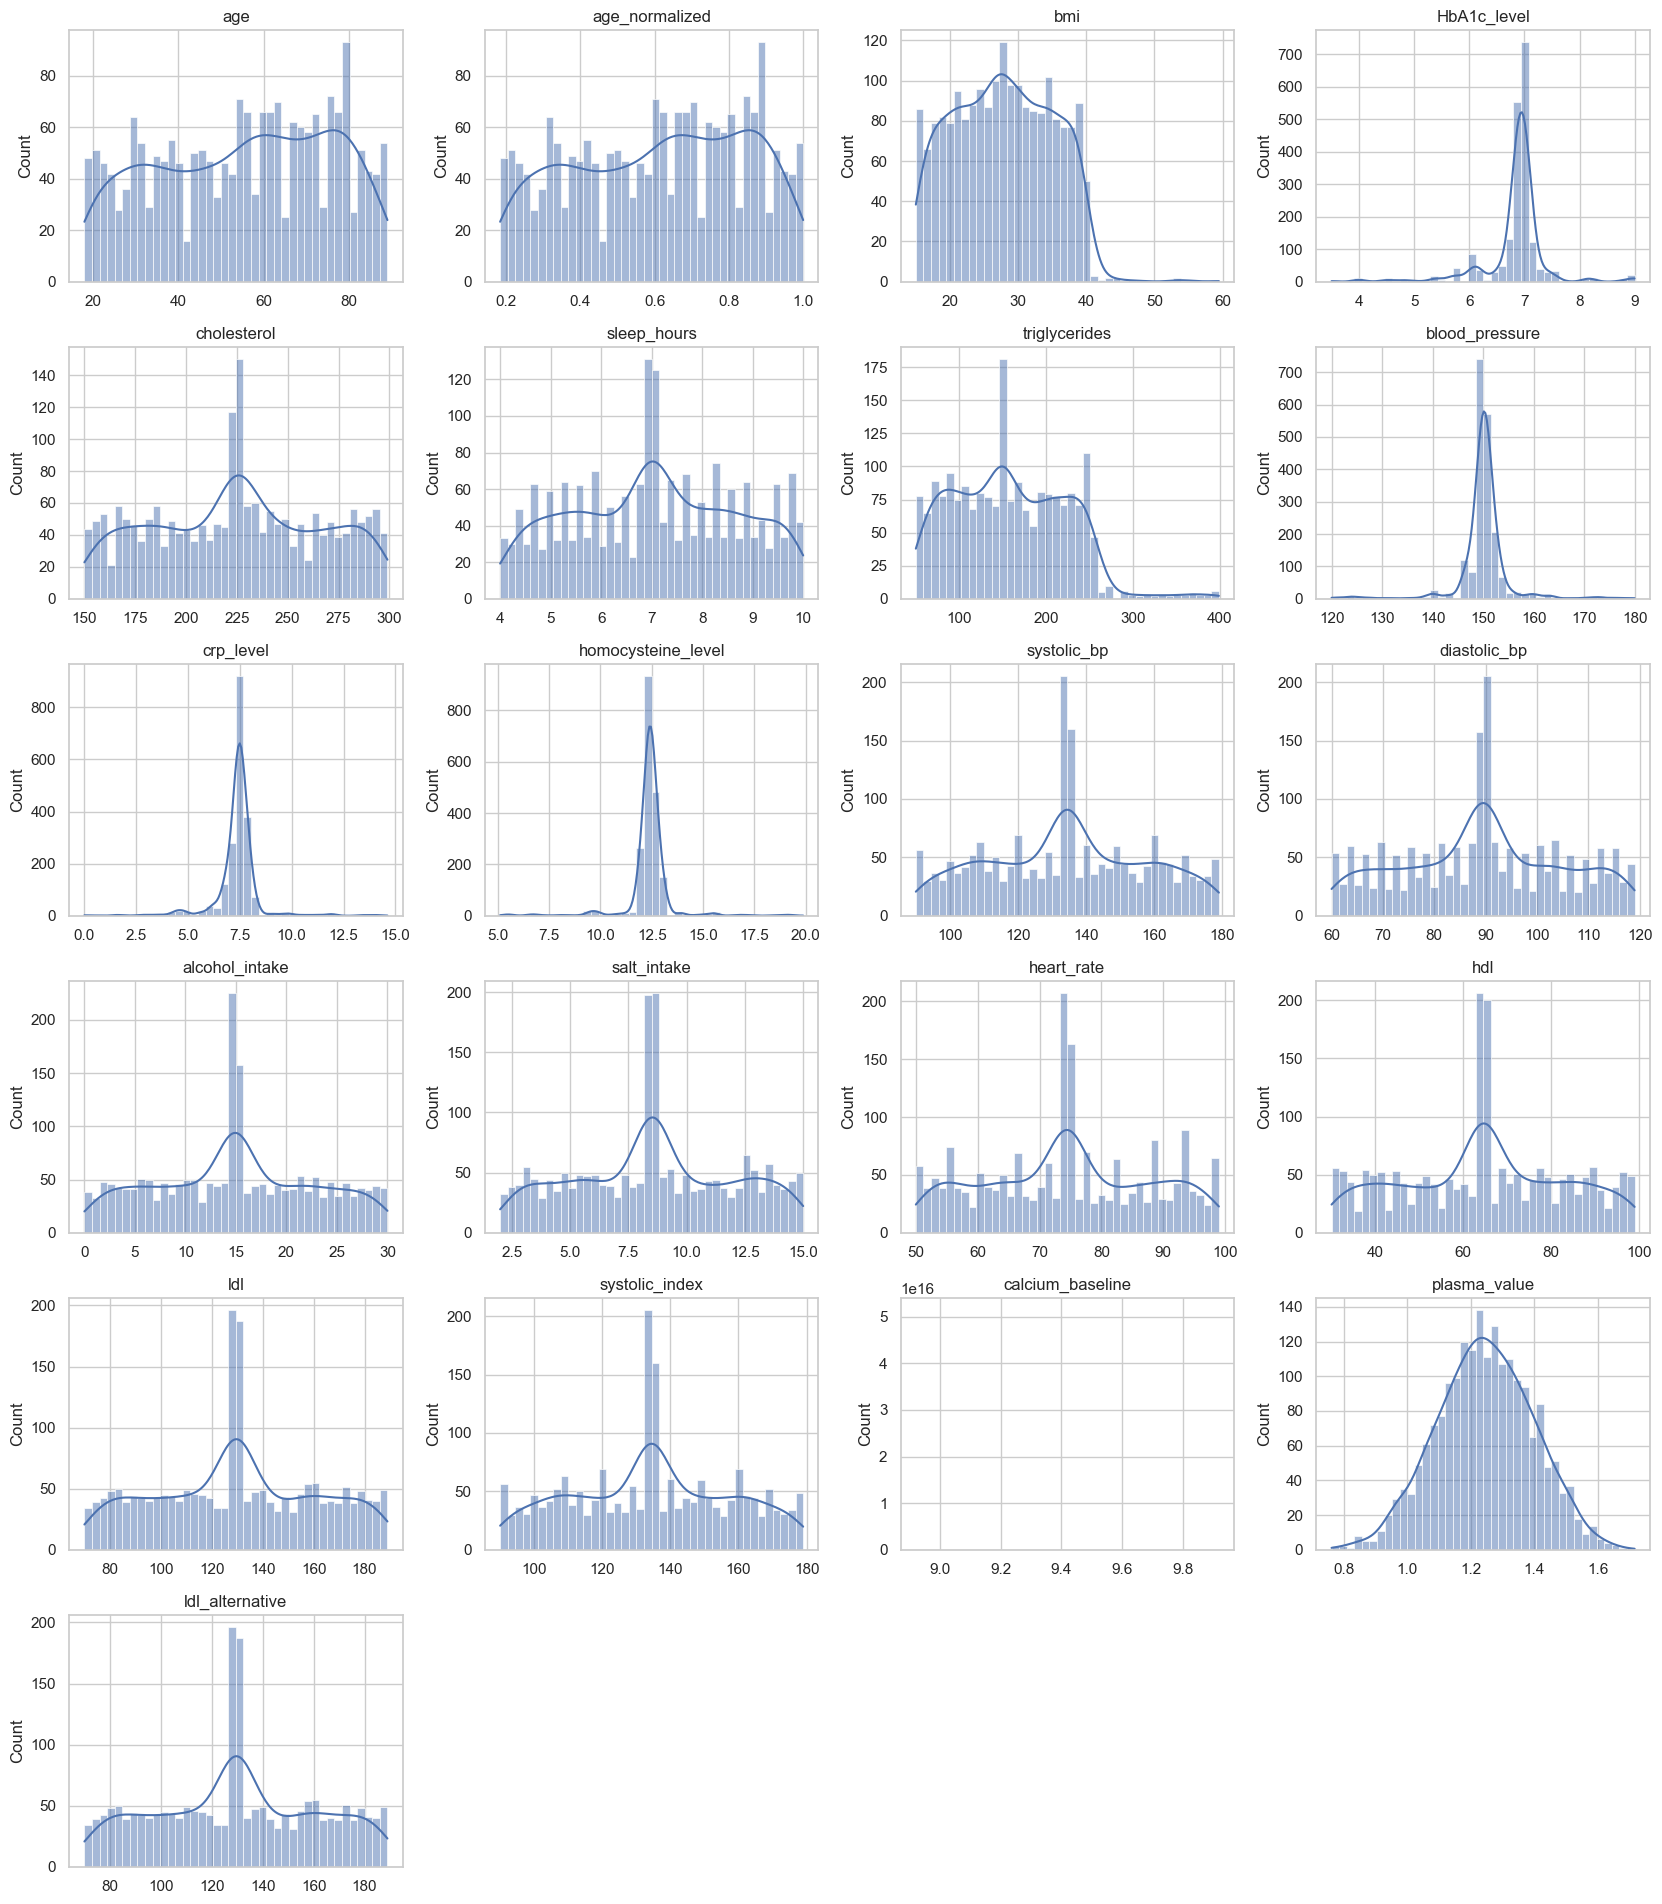

In [7]:
def grid_plot(cols, kind, ncols=4, size=(4.2, 3.2)):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0]*ncols, size[1]*nrows))
    axes = axes.ravel()
    for ax, c in zip(axes, cols):
        if kind == 'hist':
            sns.histplot(df[c], kde=True, ax=ax, bins=40)
        else:
            sns.boxplot(x=df[c], ax=ax, color='lightsteelblue')
        ax.set_title(c); ax.set_xlabel('')
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

grid_plot(num_cols, 'hist')

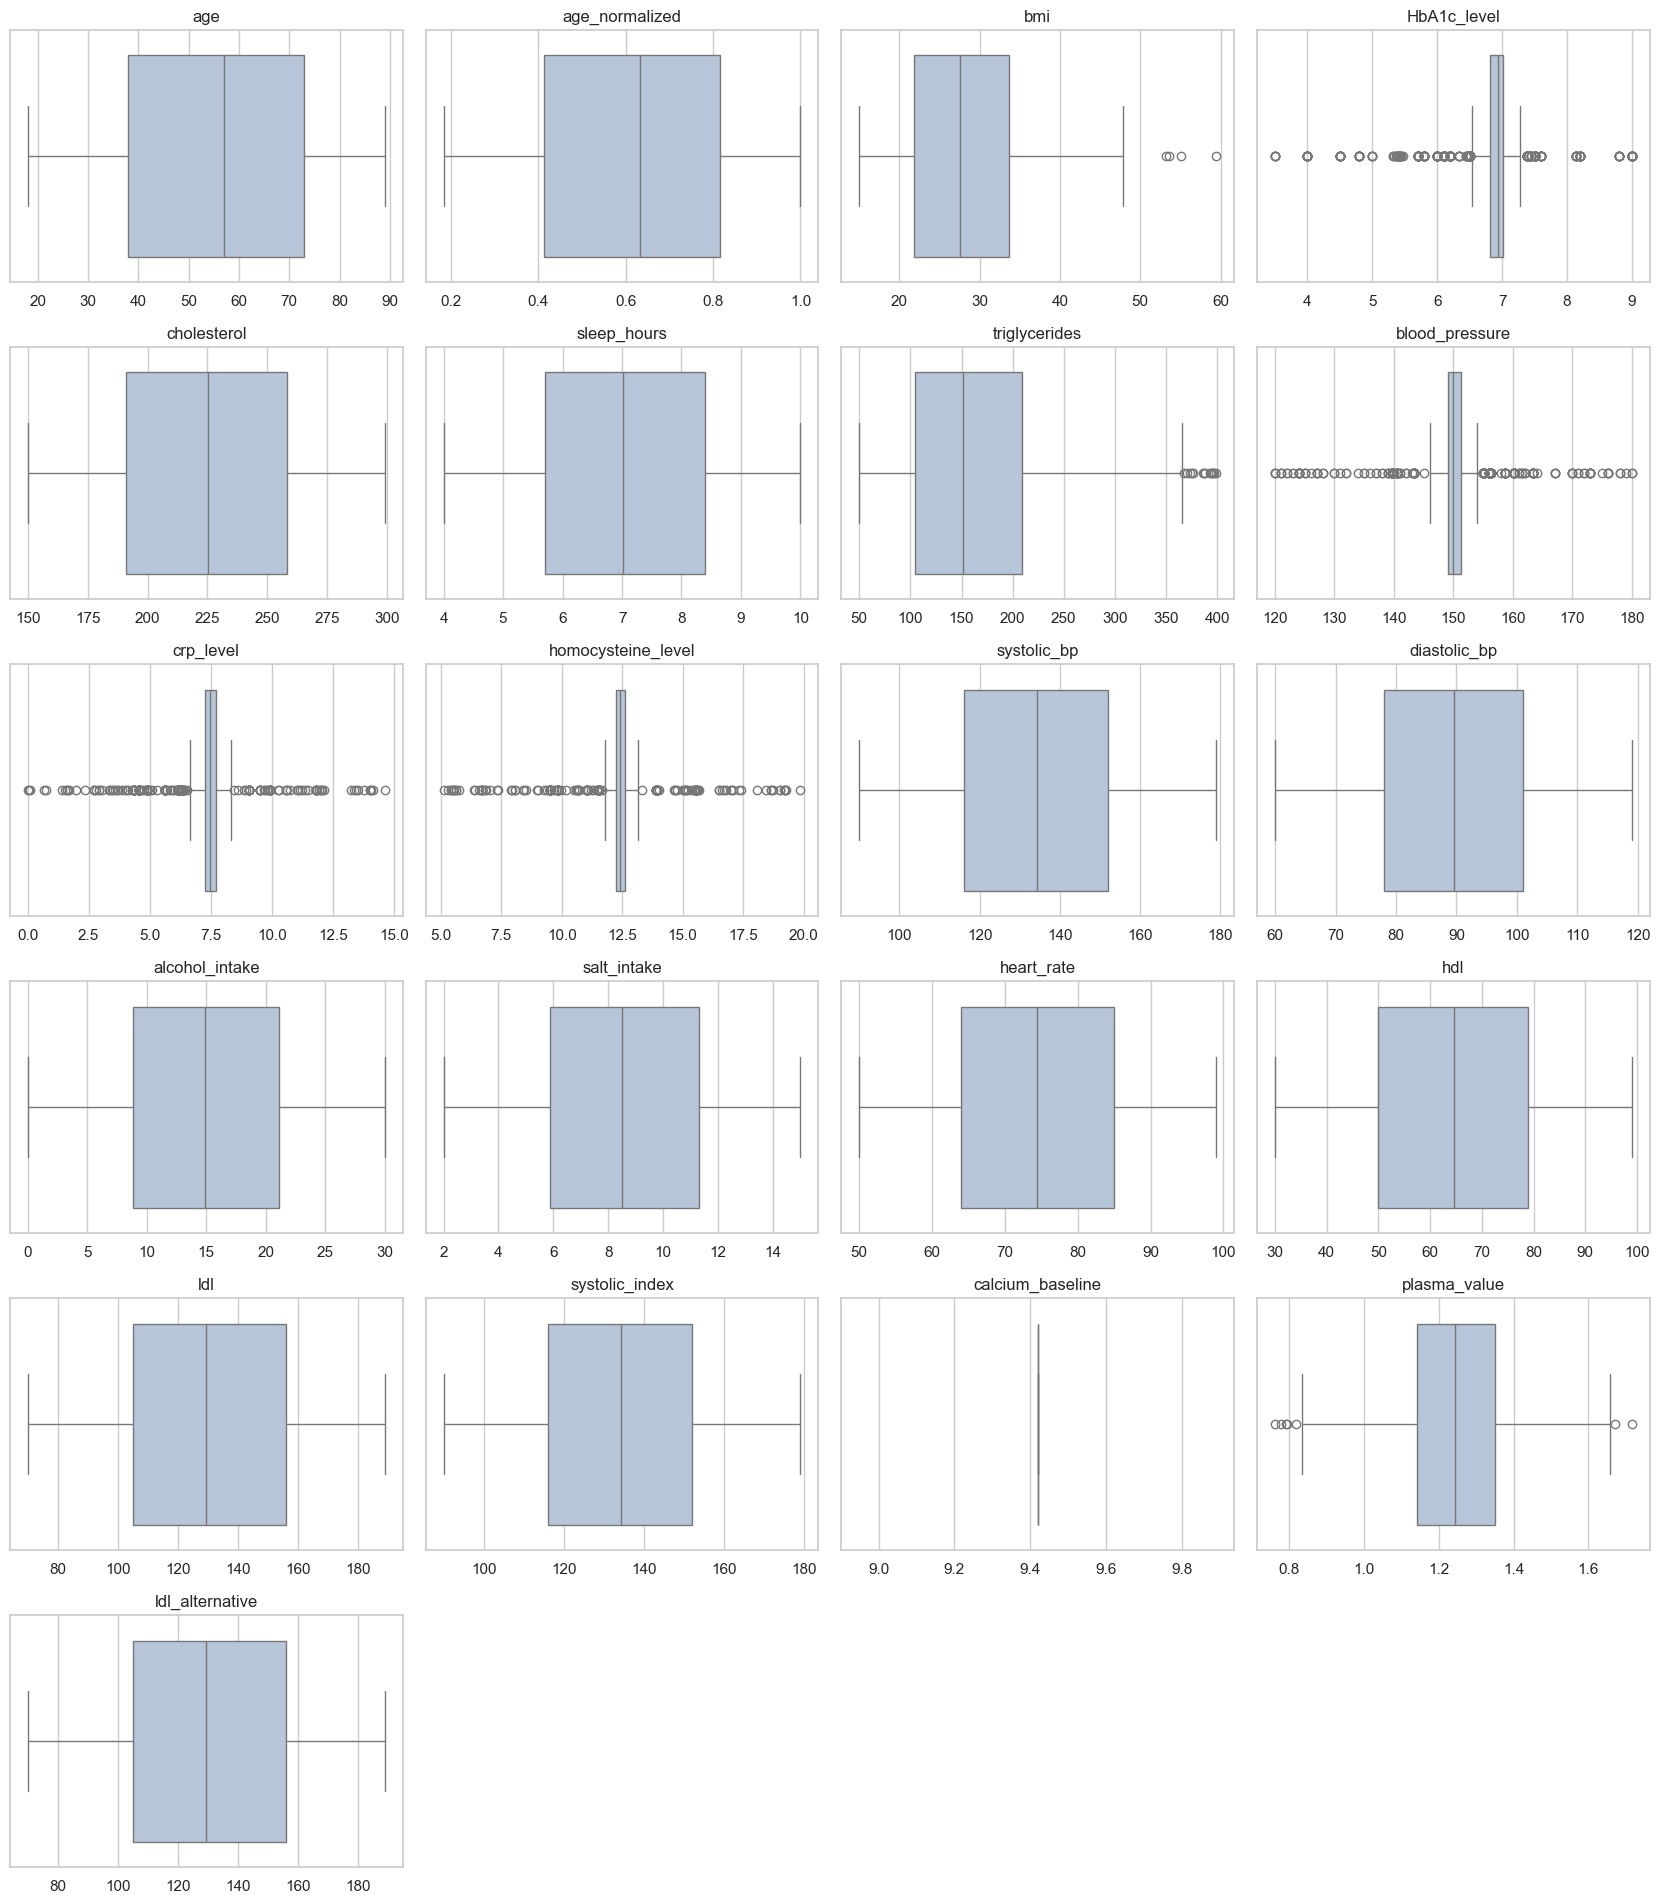

In [8]:
grid_plot(num_cols, 'box')

**Conclusões:** As distribuições agrupam-se em quatro padrões distintos:

- **Aproximadamente uniformes**: `age`, `cholesterol`, `sleep_hours`, `systolic_bp`, `diastolic_bp`,
  `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl` e `ldl`. São distribuições quase "planas", com
  frequências semelhantes ao longo de todo o intervalo.
- **Muito concentradas, com caudas longas**: `HbA1c_level`, `blood_pressure`, `crp_level` e
  `homocysteine_level`. Confirmam a curtose elevada observada em 1.3.
- **Com assimetria positiva**: `bmi` e `triglycerides`.
- **Aproximadamente normal**: `plasma_value`.
- **Constante**: `calcium_baseline`, que aparece como uma única barra.

### 2.3 Deteção de outliers

A regra do intervalo interquartil assinala como *outlier* qualquer observação que fique mais de
1.5 × IQR abaixo do primeiro quartil ou acima do terceiro. É o critério implícito nos *boxplots* da
secção anterior.

Aplicamo-la a todas as variáveis numéricas para quantificar o número de **outlier**.

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

out = pd.DataFrame({'n_outliers': {c: iqr_outliers(df[c]) for c in num_cols + [TARGET_REG]}})
out['%'] = out['n_outliers'] / len(df) * 100
out.sort_values('n_outliers', ascending=False)

,n_outliers,%
HbA1c_level,372,18.600
crp_level,228,11.400
blood_pressure,212,10.600
homocysteine_level,170,8.500
target_regression,18,0.900
triglycerides,14,0.700
plasma_value,7,0.350
bmi,4,0.200
heart_rate,0,0.000
ldl_alternative,0,0.000


**Conclusões:**
Os *outliers* concentram-se nas features leptocúrticas. Como o IQR destas variáveis é muito estreito, a regra 1.5×IQR marca como *outlier* muitos valores que são clinicamente plausíveis (por exemplo HbA1c de 5.4%).
Por isso **não os removemos automaticamente**. Na secção 3 veremos que, no caso de `HbA1c_level`, estes valores "extremos" estão associados a uma classe concreta (`HT`) e são informativos.

### 2.4 Features categóricas

A análise univariada das ***Features* Categóricas**, encontra-se desenvolvida no ponto 1.4.

## 3. Análise bivariada

### 3.1 Correlação entre features numéricas

Passamos agora a estudar **relações entre pares de variáveis**. Começamos pela matriz de correlação
entre as *features* numéricas, que serve dois objetivos distintos:

- **detetar redundância** — pares com correlação próxima de 1 contêm a mesma informação;
- **antecipar problemas de colinearidade** na regressão múltipla.

Calculamos as correlações de **Pearson** e de **Spearman**. Excluímos `calcium_baseline`, cuja correlação é indefinida por ter
variância nula.

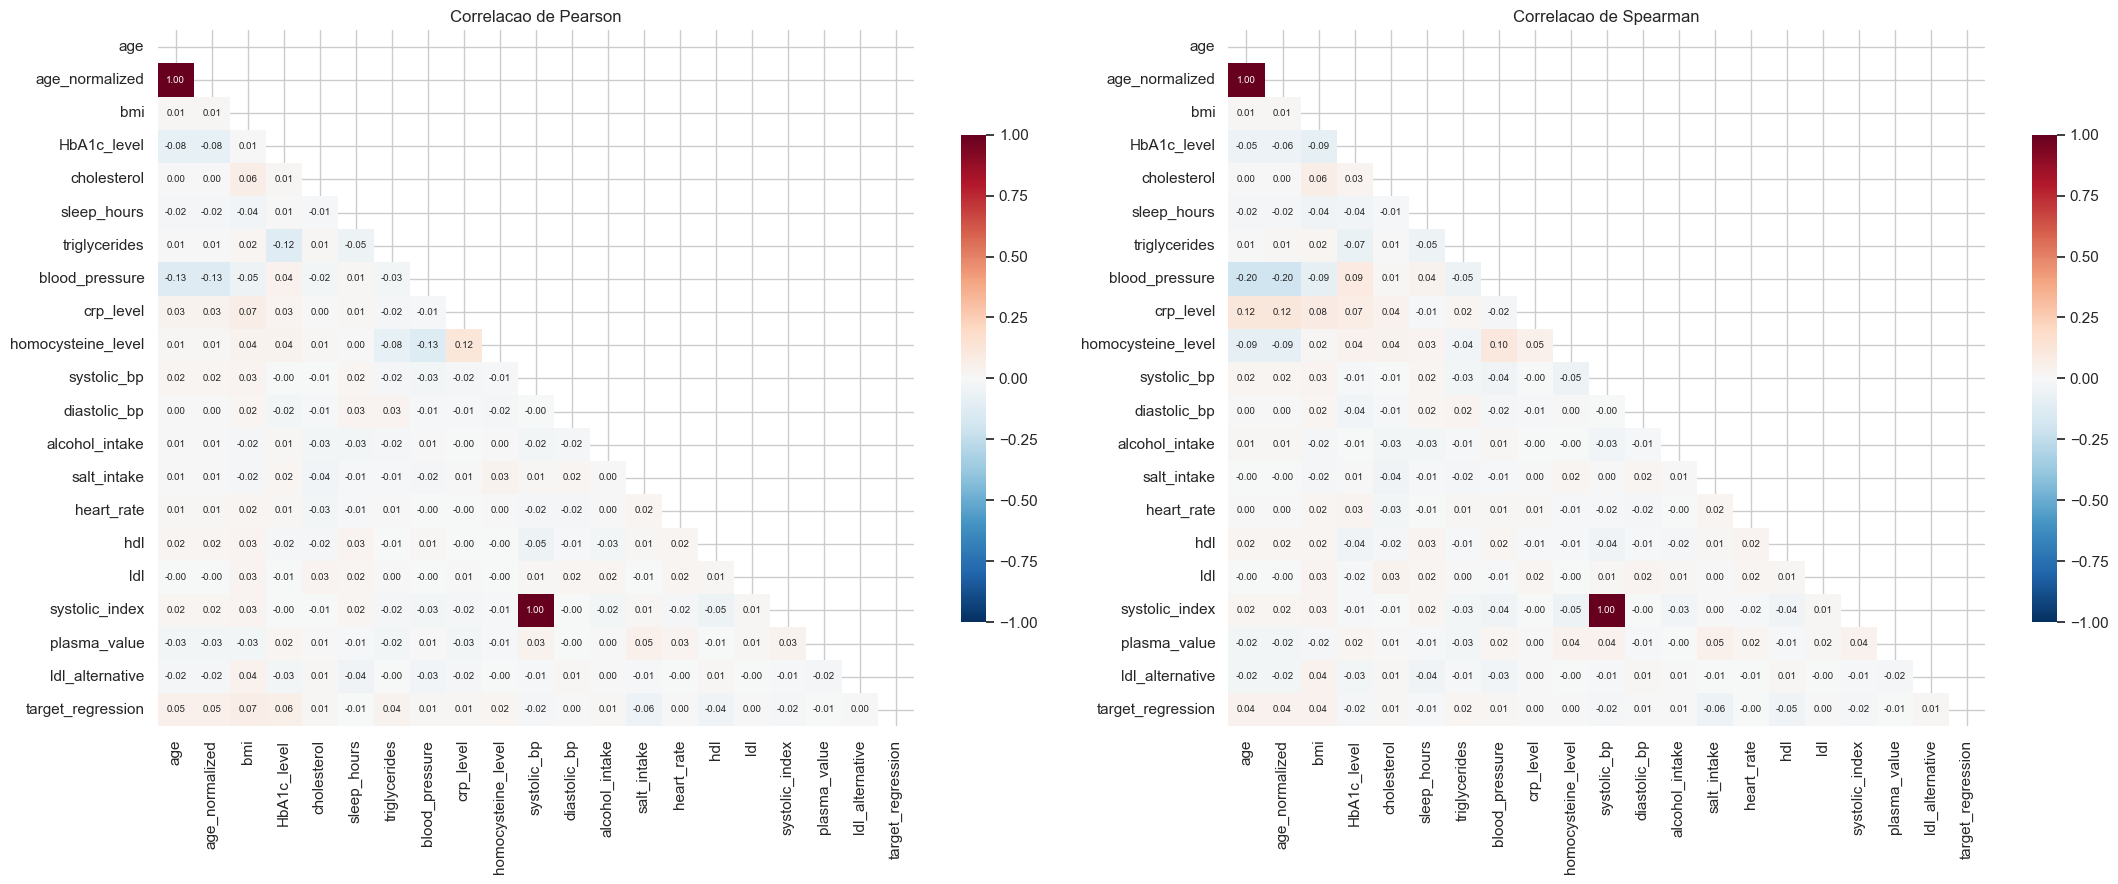

In [10]:
corr_p = df[num_cols + [TARGET_REG]].drop(columns='calcium_baseline').corr(method='pearson')
corr_s = df[num_cols + [TARGET_REG]].drop(columns='calcium_baseline').corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, m, t in zip(axes, [corr_p, corr_s], ['Pearson', 'Spearman']):
    sns.heatmap(m, mask=np.triu(np.ones_like(m, dtype=bool)), cmap='RdBu_r', vmin=-1, vmax=1,
                center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax,
                cbar_kws={'shrink': .7})
    ax.set_title(f'Correlacao de {t}')
plt.tight_layout(); plt.show()

In [11]:
upper = corr_p.where(np.triu(np.ones(corr_p.shape, dtype=bool), k=1)).stack()
high_pairs = upper[upper.abs() > 0.3].sort_values(key=abs, ascending=False).to_frame('pearson')
high_pairs

,,pearson
systolic_bp,systolic_index,1.000
age,age_normalized,1.000


**Conclusões:** Apenas **dois pares** de *features* apresentam correlação elevada, `age` com `age_normalized` e `systolic_bp` com `systolic_index`, em ambos os casos
com correlação igual ou praticamente igual a 1.

Fora destes dois pares, **as correlações entre *features* são praticamente nulas**, quase todas abaixo
de 0.05 em valor absoluto.

### 3.2 Confirmação empírica da redundância

A matriz de correlação **sugere** redundância, mas não a prova. Duas variáveis podem ter correlação 1 e não ser a mesma coluna, e podem ter correlação 0 e ainda assim estar relacionadas. Antes de remover qualquer *feature* é preciso verificar exatamente **que tipo de relação** existe.

Testamos três hipóteses: 
- se `age_normalized` é uma transformação monótona de `age`; 
- se `systolic_index` é uma cópia exata de `systolic_bp` linha a linha; 
- e se `ldl_alternative` contém os mesmos valores de `ldl` noutra ordem.

In [12]:
print('--- age vs age_normalized ---')
print('  Spearman:', round(stats.spearmanr(df.age, df.age_normalized)[0], 6))
print('  Pearson :', round(df.age.corr(df.age_normalized), 6))
expected = (df.age - 2) / 87
print('  formula (age - 2) / 87 -> residuo maximo:',
      f'{float((df.age_normalized - expected).abs().max()):.2e}')

print('\n--- systolic_bp vs systolic_index ---')
print('  iguais em todas as linhas:', (df.systolic_bp == df.systolic_index).all())

print('\n--- ldl vs ldl_alternative ---')
print('  mesmo conjunto de valores (ordenados):',
      np.allclose(np.sort(df.ldl), np.sort(df.ldl_alternative)))
print('  linhas em que coincidem:', int(df.ldl.eq(df.ldl_alternative).sum()), 'de', len(df))
print('  correlacao de Pearson:', round(df.ldl.corr(df.ldl_alternative), 4))

--- age vs age_normalized ---
  Spearman: 0.999951
  Pearson : 1.0
  formula (age - 2) / 87 -> residuo maximo: 9.89e-07

--- systolic_bp vs systolic_index ---
  iguais em todas as linhas: True

--- ldl vs ldl_alternative ---
  mesmo conjunto de valores (ordenados): True
  linhas em que coincidem: 18 de 2000
  correlacao de Pearson: -0.0049


**Conclusões:**

- **`age_normalized` é uma reescala determinística de `age`.** **É redundante**, as duas colunas contêm literalmente a mesma informação, e por isso basta manter `age`.
- **`systolic_index` é uma cópia exata de `systolic_bp`**, igual em todas as 2000 linhas. A definição
  vaga do enunciado ("índice secundário de dinâmica de pressão hemodinâmica") não corresponde a nada de
  novo nos dados. **É redundante.**
- `ldl_alternative` tem exatamente o mesmo conjunto de valores de
  `ldl`, mas coincide com ela em apenas 18 das 2000 linhas, e a correlação entre ambas é praticamente nula. Isto é compatível com uma **permutação
  aleatória das linhas de `ldl`**, do qual a coluna tem a distribuição certa, mas o valor de cada paciente não lhe pertence.

### 3.3 Coerência entre features derivadas e as suas variáveis de origem

O enunciado indica que `age_level` e `bmi_level` são categorias derivadas de `age` e `bmi`. Pelos nomes,
`low_hdl_cholesterol` e `high_ldl_cholesterol` serão *flags* construídas a partir de `hdl` e `ldl`.

Vale a pena verificar se essa correspondência se confirma nos dados. Comparamos cada *flag* com o limiar clínico habitual (HDL < 40 e LDL ≥ 130) para avaliar a nitidez.

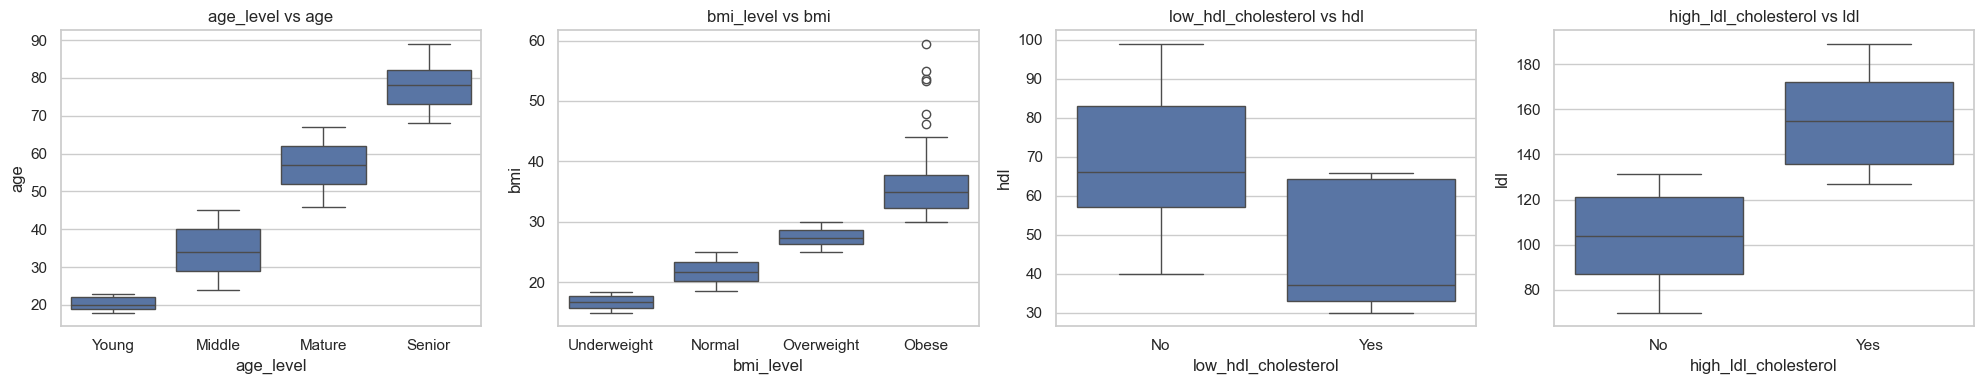

hdl < 40             False  True 
low_hdl_cholesterol              
No                    1647      0
Yes                    105    248

ldl >= 130            False  True 
high_ldl_cholesterol              
No                      940     38
Yes                     116    906


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.boxplot(data=df, x='age_level', y='age',
            order=['Young','Middle','Mature','Senior'], ax=axes[0])
sns.boxplot(data=df, x='bmi_level', y='bmi',
            order=['Underweight','Normal','Overweight','Obese'], ax=axes[1])
sns.boxplot(data=df, x='low_hdl_cholesterol', y='hdl', ax=axes[2])
sns.boxplot(data=df, x='high_ldl_cholesterol', y='ldl', ax=axes[3])
for ax in axes: ax.set_title(f'{ax.get_xlabel()} vs {ax.get_ylabel()}')
plt.tight_layout(); plt.show()

print(pd.crosstab(df.low_hdl_cholesterol, df.hdl < 40, colnames=['hdl < 40']))
print()
print(pd.crosstab(df.high_ldl_cholesterol, df.ldl >= 130, colnames=['ldl >= 130']))

**Conclusões:** `age_level` e `bmi_level` correspondem a **discretizações nítidas** de `age` e `bmi`.

Já nas variáveis `low_hdl_cholesterol` e `high_ldl_cholesterol` há alguma sobreposição (o limiar não é perfeitamente nítido), mas a associação é forte.

Em qualquer dos casos, as quatro variáveis são **parcialmente redundantes** com as suas variáveis de
origem. Num modelo linear, a prática habitual é ficar com a variável contínua, que preserva mais
informação do que a sua versão agrupada em intervalos.

### 3.4 Features numéricas vs `target_regression`

Esta análise vai nos vai orientar na escolha do preditor para
a regressão linear simples e do conjunto de preditores para a múltipla.

Calculamos três medidas complementares, para não depender de uma só:

- a **correlação de Pearson**, que mede a força da relação **linear**;
- a **correlação de Spearman**, que mede relações monótonas ainda que curvas;
- a **informação mútua**, que capta qualquer tipo de dependência, incluindo não monótona.

Acrescentamos o **p-value** do teste de Pearson, que testa a hipótese nula de ausência de relação (β₁ = 0).

In [15]:
# Working set: excludes the constant feature and the two redundant ones confirmed in 3.2
num_feats = [c for c in num_cols
             if c not in ('calcium_baseline', 'age_normalized', 'systolic_index')]

rel_reg = pd.DataFrame({
    'pearson': [df[c].corr(df[TARGET_REG]) for c in num_feats],
    'spearman': [df[c].corr(df[TARGET_REG], method='spearman') for c in num_feats],
    'p_value_pearson': [stats.pearsonr(df[c], df[TARGET_REG])[1] for c in num_feats],
}, index=num_feats)
rel_reg['mutual_info'] = mutual_info_regression(df[num_feats], df[TARGET_REG],
                                                random_state=RANDOM_STATE)
rel_reg = rel_reg.sort_values('pearson', key=abs, ascending=False)
rel_reg

,pearson,spearman,p_value_pearson,mutual_info
bmi,0.070,0.044,0.002,0.073
salt_intake,-0.062,-0.062,0.005,0.125
HbA1c_level,0.055,-0.023,0.013,0.086
age,0.054,0.043,0.017,0.041
hdl,-0.040,-0.046,0.074,0.131
triglycerides,0.037,0.019,0.096,0.104
systolic_bp,-0.018,-0.016,0.426,0.129
homocysteine_level,0.016,0.002,0.474,0.066
blood_pressure,0.015,0.011,0.509,0.049
cholesterol,0.011,0.011,0.616,0.121


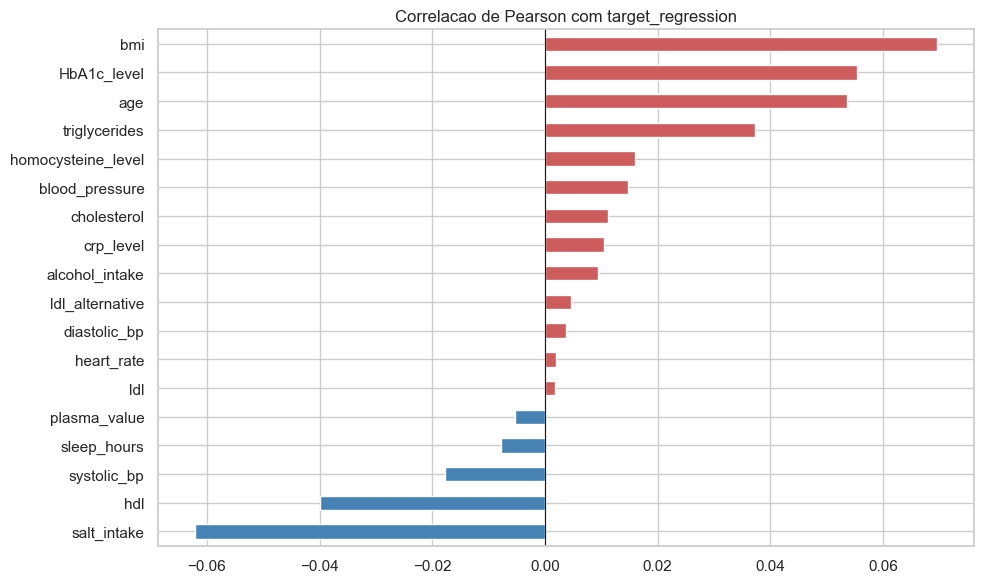

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
serie = rel_reg['pearson'].sort_values()
serie.plot.barh(ax=ax, color=np.where(serie > 0, 'indianred', 'steelblue'))
ax.axvline(0, color='k', lw=.8)
ax.set_title('Correlacao de Pearson com target_regression')
plt.tight_layout(); plt.show()

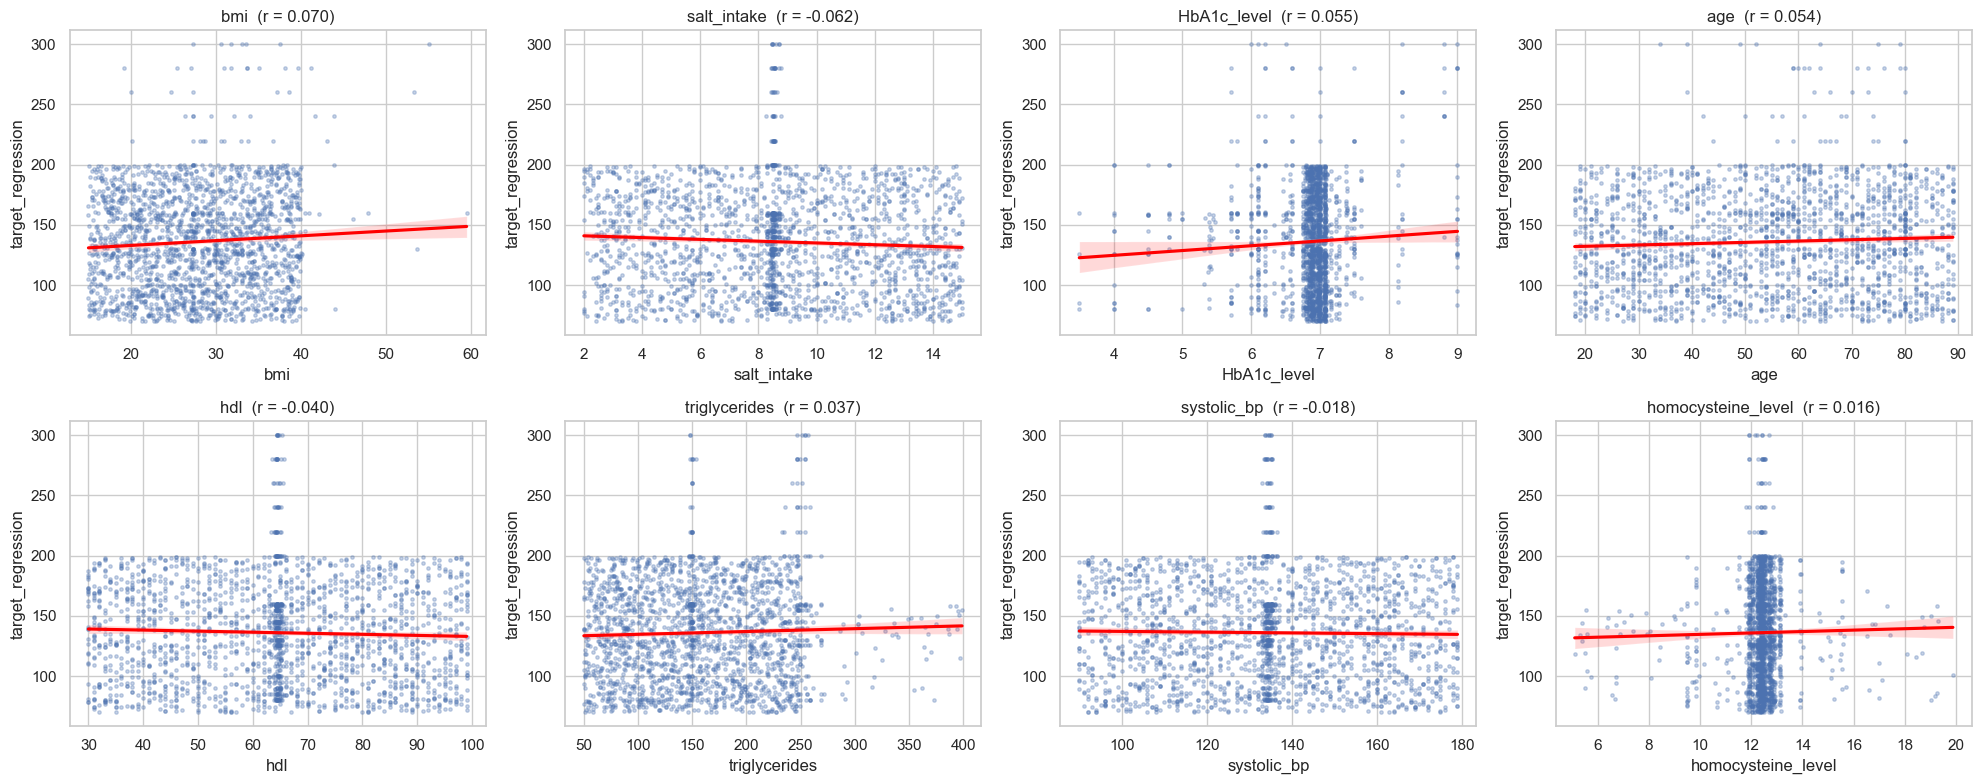

In [ ]:
top = rel_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top):
    sns.regplot(data=df, x=c, y=TARGET_REG, ax=ax,
                scatter_kws={'s': 6, 'alpha': .3}, line_kws={'color': 'red'})
    ax.set_title(f'{c}  (r = {rel_reg.loc[c, "pearson"]:.3f})')
plt.tight_layout(); plt.show()

**Conclusões:**

**Nenhuma *feature* numérica tem uma relação linear relevante com `target_regression`.** O maior valor
absoluto de correlação é o de `bmi`, com r ≈ 0.070. Seguem-se `salt_intake` (−0.062), `HbA1c_level`
(0.055) e `age` (0.054), que são estatisticamente significativos (p < 0.05) devido ao tamanho da amostra (n = 2000). Todos os restantes ficam ainda mais próximos de zero. Nas retas ajustadas dos
gráficos de dispersão isto é visível a olho nu, as nuvens de pontos são praticamente horizontais.

---

### Faz sentido ter o MI?
A coluna da **informação mútua** merece um aviso. O seu topo (`alcohol_intake` ≈ 0.154, `sleep_hours`
≈ 0.144, `diastolic_bp` ≈ 0.142, `hdl` ≈ 0.131) **não coincide** com o das correlações — a
`bmi`, que é a *feature* mais correlacionada, cabe apenas 0.073. Como se verá em 3.11, estas são
precisamente as variáveis afetadas por um artefacto na construção dos dados, e o estimador de
informação mútua é sensível a esse artefacto. **Não usamos a MI como critério de seleção neste
dataset.** 


---


É de se esperar um **R² muito baixo**, tanto na regressão linear simples
como na múltipla. A variável com maior efeito sobre `target_regression` é, como veremos a seguir, a
própria `target_class`, que não pode ser usada como preditor.

### 3.5 Features categóricas vs `target_regression`

Para avaliar a relação entre uma variável categórica e uma variável contínua, aplicamos dois testes:

- a **ANOVA** (teste F), que é paramétrico e assume normalidade e homogeneidade de variâncias;
- o **Kruskal-Wallis**, que é a alternativa não paramétrica, baseada em ordens.

Calculamos também o **η² (eta quadrado)**, que mede a **proporção da variância** de `target_regression`
explicada por cada variável categórica. É esta medida de tamanho de efeito, e não o p-value, que nos diz
se a variável é **praticamente** útil.

In [ ]:
rows = []
for c in cat_cols + [TARGET_CLS]:
    groups = [g[TARGET_REG].values for _, g in df.groupby(c)]
    F, p_anova = stats.f_oneway(*groups)
    H, p_kw = stats.kruskal(*groups)
    ss_between = sum(len(g) * (g.mean() - df[TARGET_REG].mean())**2 for g in groups)
    eta2 = ss_between / ((df[TARGET_REG] - df[TARGET_REG].mean())**2).sum()
    rows.append({'feature': c, 'F_anova': F, 'p_anova': p_anova,
                 'p_kruskal': p_kw, 'eta2': eta2})
cat_reg = pd.DataFrame(rows).set_index('feature').sort_values('eta2', ascending=False)
cat_reg_show = cat_reg.copy()
for col in ['p_anova', 'p_kruskal']:
    cat_reg_show[col] = cat_reg_show[col].map('{:.3g}'.format)
cat_reg_show

,F_anova,p_anova,p_kruskal,eta2
feature,,,,
target_class,27.881,1.14e-12,5.31e-06,0.027
smoking,6.043,0.00242,0.00447,0.006
age_level,3.593,0.0131,0.0391,0.005
bmi_level,2.245,0.0812,0.33,0.003
physical_activity,3.068,0.0467,0.333,0.003
sugar_consumption,0.926,0.396,0.485,0.001
family_history,1.842,0.175,0.187,0.001
high_ldl_cholesterol,1.541,0.215,0.356,0.001
education_level,0.700,0.496,0.431,0.001


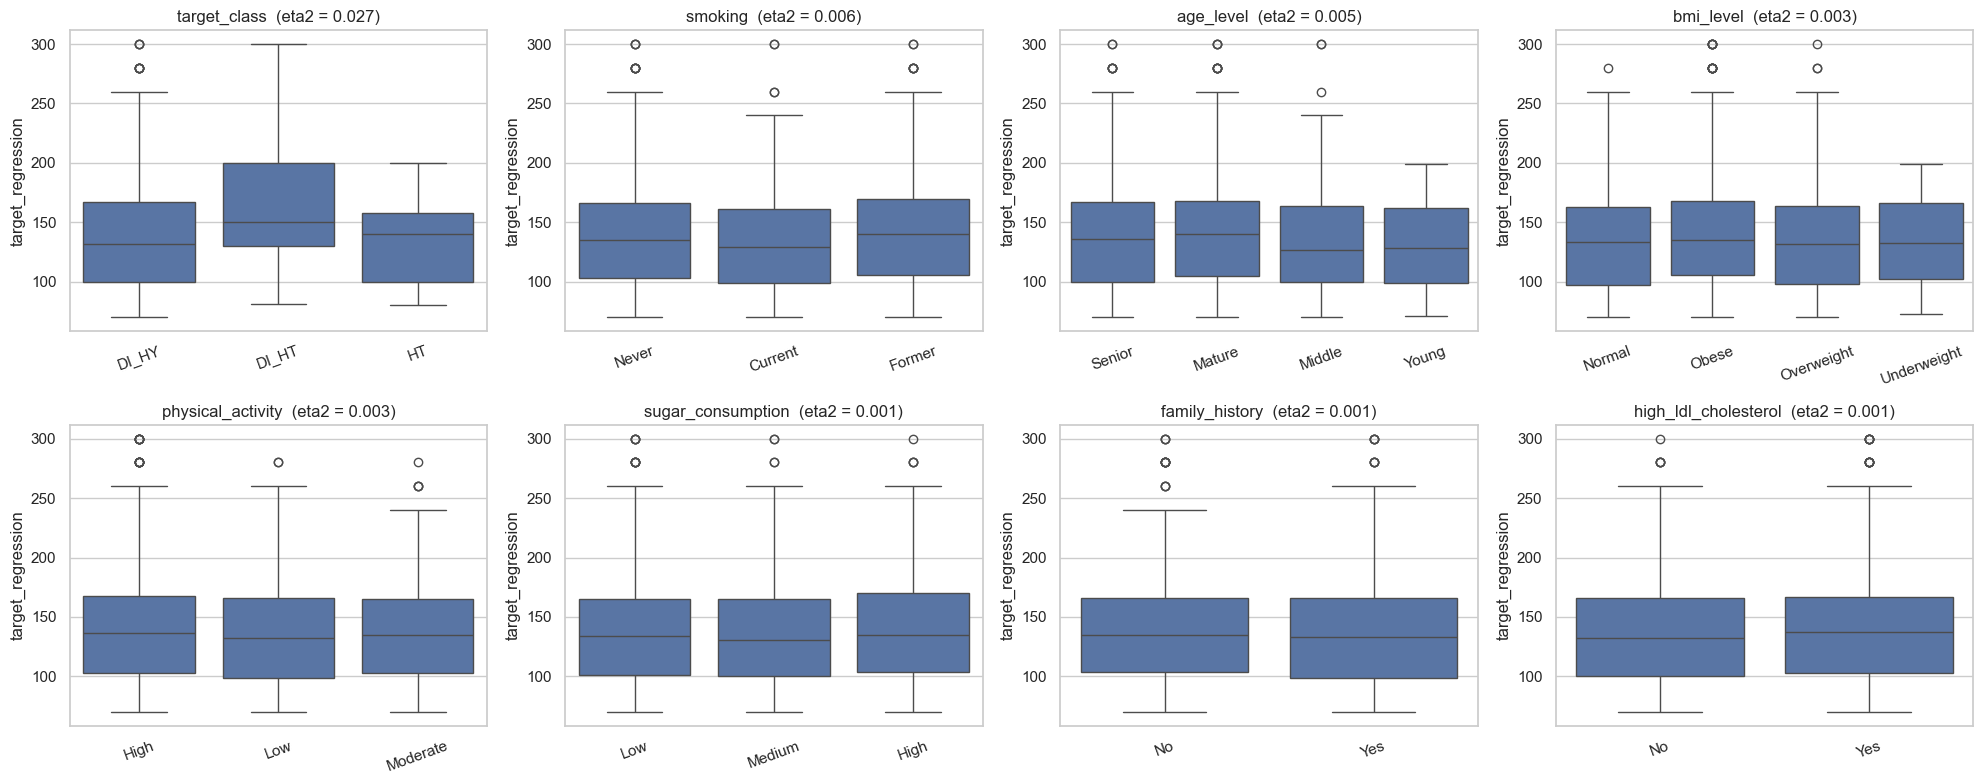

In [ ]:
plot_cats = cat_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, plot_cats):
    sns.boxplot(data=df, x=c, y=TARGET_REG, ax=ax)
    ax.set_title(f'{c}  (eta2 = {cat_reg.loc[c, "eta2"]:.3f})')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Conclusões:** A variável com maior efeito sobre `target_regression` é, a própria
**`target_class`**.

Todas as restantes variáveis categóricas têm **η² praticamente nulo** (≤ 0.006). Algumas chegam a ter
p-value abaixo de 0.05, mas sem qualquer relevância
prática.

Confirma-se assim o diagnóstico da secção anterior, onde **não existe, no conjunto de *features* disponíveis, não explicam praticamente nada da variabilidade de `target_regression`**.

### 3.6 Features numéricas vs `target_class`

Usamos o **teste de Kruskal-Wallis** para comparar a distribuição de cada *feature* entre as três
classes. Optamos pela versão não paramétrica porque, como vimos, as distribuições estão longe da
normalidade e as classes têm dimensões muito diferentes.

Acrescentamos o **η²** como medida de tamanho de efeito e a **informação mútua**, para comparação.

In [ ]:
classes = df[TARGET_CLS].value_counts().index.tolist()
rows = []
for c in num_feats:
    groups = [df.loc[df[TARGET_CLS] == k, c] for k in classes]
    H, p = stats.kruskal(*groups)
    ss_b = sum(len(g) * (g.mean() - df[c].mean())**2 for g in groups)
    eta2 = ss_b / ((df[c] - df[c].mean())**2).sum()
    rows.append({'feature': c, **{f'mean_{k}': g.mean() for k, g in zip(classes, groups)},
                 'kruskal_H': H, 'p_value': p, 'eta2': eta2})
num_cls = pd.DataFrame(rows).set_index('feature')
num_cls['mutual_info'] = mutual_info_classif(df[num_feats], df[TARGET_CLS],
                                             random_state=RANDOM_STATE)
num_cls = num_cls.sort_values('eta2', ascending=False)
num_cls_show = num_cls.copy()
num_cls_show['p_value'] = num_cls_show['p_value'].map('{:.3g}'.format)
num_cls_show

,mean_DI_HY,mean_HT,mean_DI_HT,kruskal_H,p_value,eta2,mutual_info
feature,,,,,,,
HbA1c_level,6.936,5.374,6.979,307.152,2.01e-67,0.410,0.206
triglycerides,151.159,217.040,227.074,170.839,7.99e-38,0.105,0.242
age,54.419,63.060,60.706,23.972,6.23e-06,0.013,0.029
crp_level,7.390,7.514,6.881,2.422,0.298,0.010,0.206
blood_pressure,150.299,149.190,148.195,48.963,2.33e-11,0.009,0.192
bmi,27.623,29.051,29.987,11.401,0.00334,0.006,0.103
homocysteine_level,12.373,12.606,12.194,20.806,3.03e-05,0.004,0.184
ldl_alternative,129.270,136.217,133.376,5.109,0.0777,0.003,0.007
sleep_hours,7.062,6.807,7.061,4.004,0.135,0.001,0.222


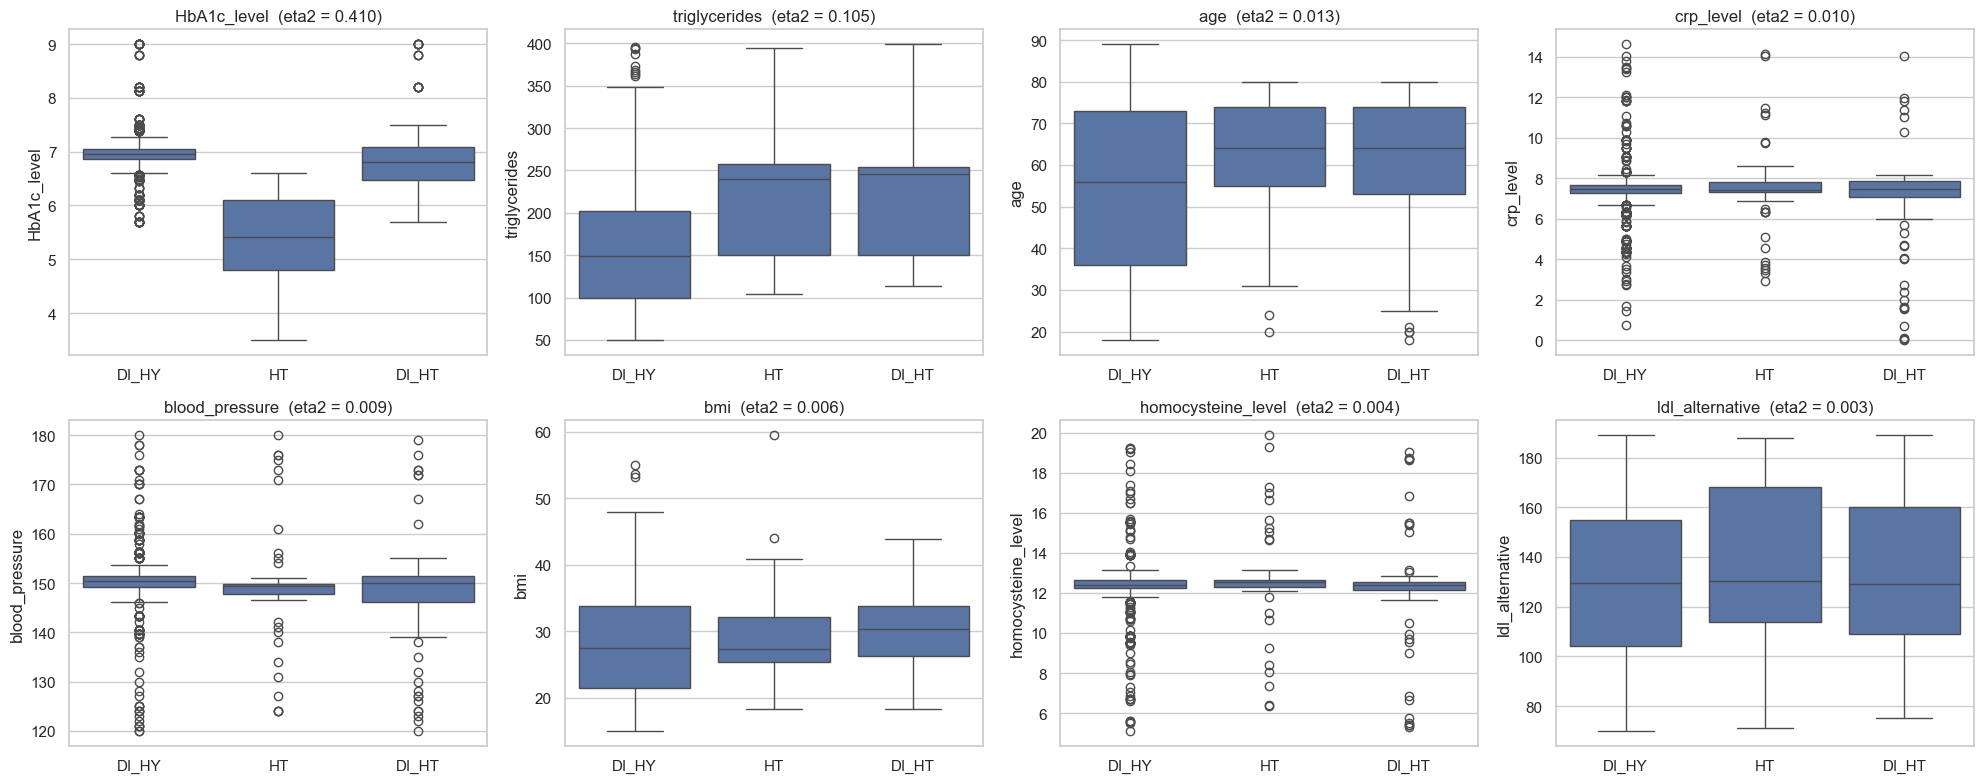

In [ ]:
top_cls = num_cls.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top_cls):
    sns.boxplot(data=df, x=TARGET_CLS, y=c, order=classes, ax=ax)
    ax.set_title(f'{c}  (eta2 = {num_cls.loc[c, "eta2"]:.3f})'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

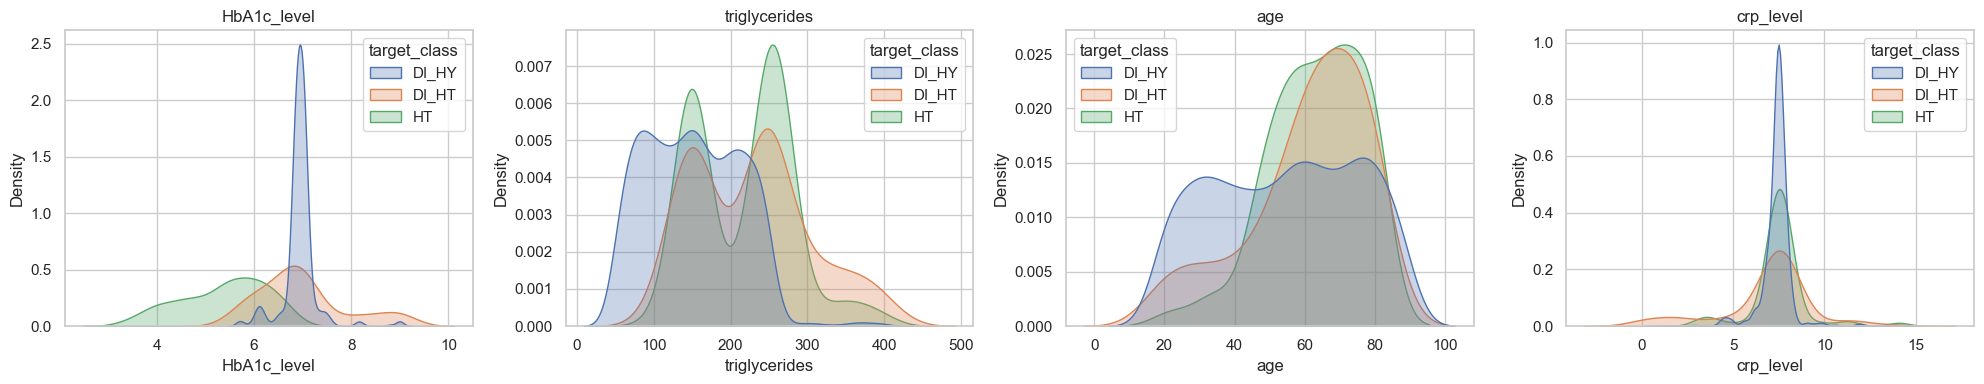

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, num_cls.index[:4]):
    sns.kdeplot(data=df, x=c, hue=TARGET_CLS, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Conclusões:**

Ordenadas por tamanho de efeito, destacam-se:

- **`HbA1c_level` (η² = 0.41, Kruskal-Wallis H = 307, p ≈ 2e-67)** é a *feature* mais
  discriminativa, explica cerca de **41% da variância** da sua própria distribuição entre classes. Isto faz sentido clinicamente, porque `HbA1c` é o marcador de diabetes e `HT` é a única classe sem componente diabética. É a feature que melhor separa `HT` das outras.
- **`triglycerides` (η² = 0.105, p ≈ 8e-38)**: valores substancialmente mais altos em `DI_HT` (≈ 227) e
  `HT` (≈ 217) do que em `DI_HY` (≈ 151).
- Com efeitos muito menores mas ainda estatisticamente detetáveis: `age` (η² = 0.013), `blood_pressure` (0.009), `bmi` (0.006) e `homocysteine_level` (0.004).
- **Apenas 6 das 18 *features* numéricas** apresentam diferenças significativas entre classes. As
  restantes, incluindo `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake` e
  `salt_intake`, têm distribuições praticamente idênticas nas três classes e são, do ponto de vista do
  seu valor clínico, **pouco informativas**.


---

### É necessário?

**Contradição aparente com a informação mútua:** A coluna `mutual_info` atribui valores elevados e
muito semelhantes precisamente a várias das *features* que os testes classificam como irrelevantes,
enquanto `HbA1c_level` — a mais discriminativa — nem sequer aparece no topo. Esta inconsistência não é
um erro de cálculo: tem uma causa concreta nos dados, identificada na secção 3.11. Até lá, **damos
prioridade aos testes estatísticos com tamanho de efeito**, que medem diferenças no valor das variáveis.

### 3.7 Features categóricas vs `target_class` (χ² e V de Cramér)

Para medir a associação entre duas variáveis categóricas usamos o **teste do qui-quadrado** sobre a
tabela de contingência, que testa a independência entre elas.

O χ² tem, porém, uma limitação conhecida, no qual o seu valor cresce com o tamanho da amostra, pelo que com
n = 2000 quase tudo acaba por ser "significativo". Para medir a **força** da associação usamos por isso
o **V de Cramér**, que normaliza o χ² para um valor entre 0 e 1 e é interpretável como medida de efeito
(valores abaixo de 0.1 correspondem, a associações fracas).

In [ ]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), chi2, p

rows = []
for c in cat_cols:
    v, chi2, p = cramers_v(df[c], df[TARGET_CLS])
    rows.append({'feature': c, 'chi2': chi2, 'p_value': p, 'cramers_v': v})
cat_cls = pd.DataFrame(rows).set_index('feature').sort_values('cramers_v', ascending=False)
cat_cls_show = cat_cls.copy()
cat_cls_show['p_value'] = cat_cls_show['p_value'].map('{:.3g}'.format)
cat_cls_show

,chi2,p_value,cramers_v
feature,,,
low_hdl_cholesterol,31.042,1.82e-07,0.125
age_level,50.711,3.39e-09,0.113
bmi_level,46.506,2.35e-08,0.108
physical_activity,19.793,0.000549,0.070
education_level,15.257,0.0042,0.062
sugar_consumption,13.796,0.00797,0.059
employment_status,13.748,0.00814,0.059
smoking,13.380,0.00956,0.058
family_history,6.147,0.0462,0.055


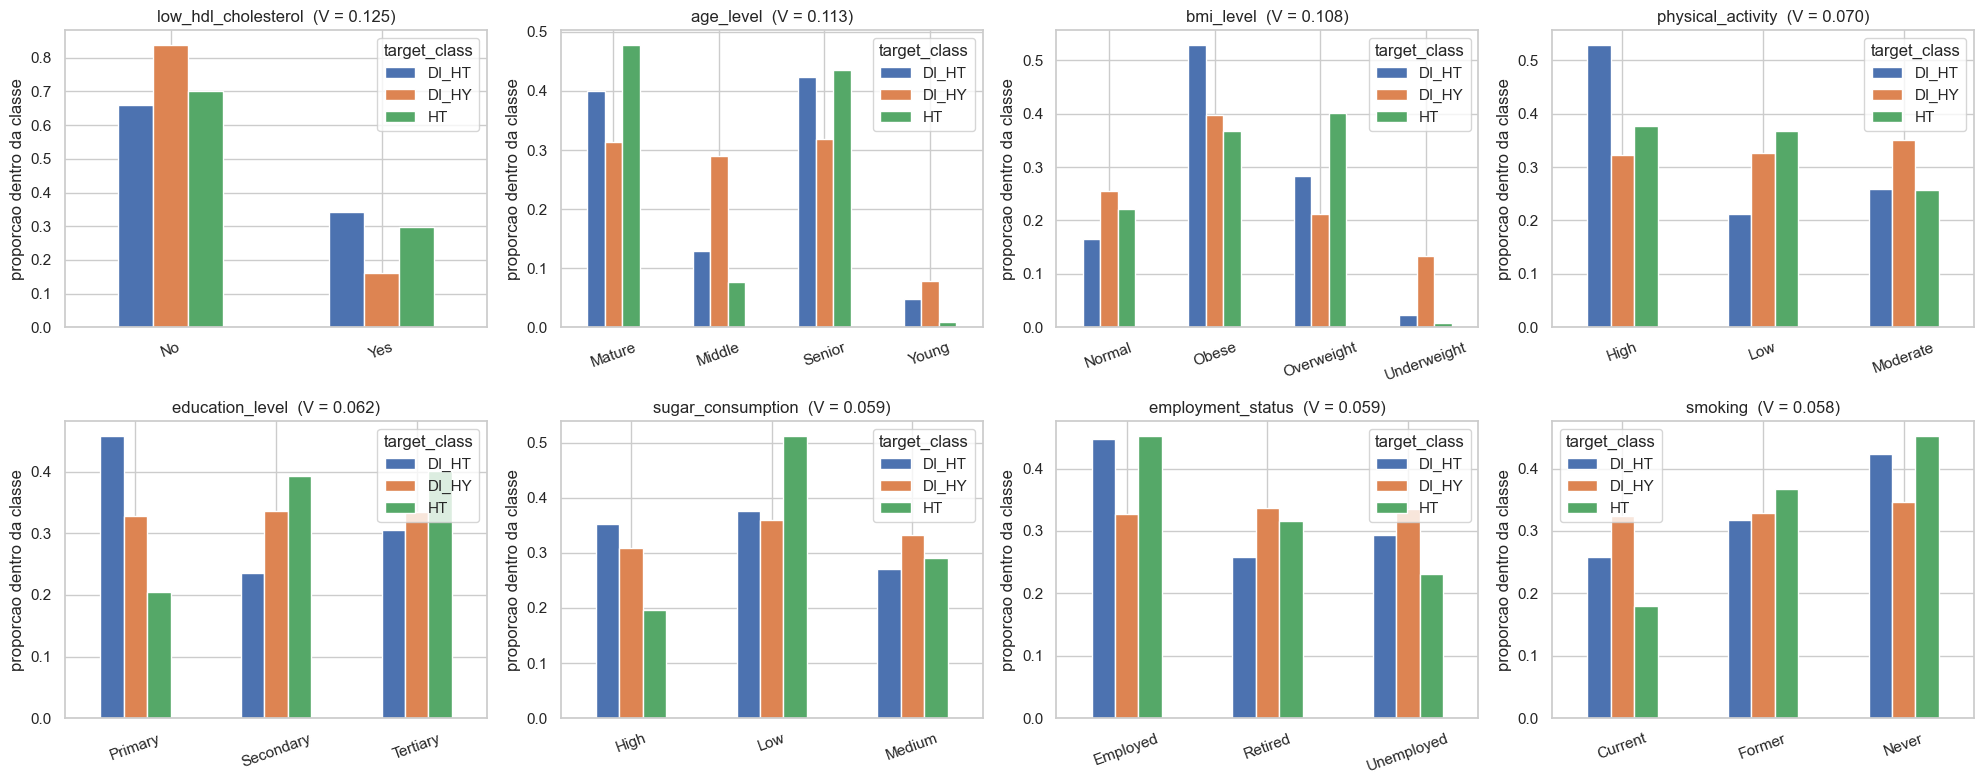

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, cat_cls.index[:8]):
    ct = pd.crosstab(df[c], df[TARGET_CLS], normalize='columns')   # perfil de cada classe
    ct.plot.bar(ax=ax, rot=20)
    ax.set_title(f'{c}  (V = {cat_cls.loc[c, "cramers_v"]:.3f})')
    ax.set_xlabel(''); ax.set_ylabel('proporcao dentro da classe')
plt.tight_layout(); plt.show()

**Conclusões:** As associações mais fortes são as de `low_hdl_cholesterol`, `age_level` e `bmi_level`,
mas **todas são fracas em termos absolutos** (V = 0.125, 0.113 e 0.108, respetivamente). `age_level` e `bmi_level` confirmam, o efeito de `age` e `bmi` já detetado em 3.6.

**`low_hdl_cholesterol` está associada à classe, apesar de `hdl` não estar**. Uma *flag* derivada de uma variável sem
sinal não deveria, em princípio, ter sinal.

Várias variáveis, `physical_activity`, `education_level`, `smoking`, `employment_status`, têm p-value
abaixo de 0.05 mas V ≈ 0.06. Repete-se o padrão já visto, no qual com n = 2000, efeitos minúsculos tornam-se
estatisticamente significativos sem terem **relevância prática**.

Por fim, **`gender` e `stress_level` não apresentam qualquer associação** com a classe (p > 0.2). São as
duas candidatas mais claras a *features* não informativas entre as categóricas.

### 3.8 Pressupostos da LDA: normalidade e covariância por classe

A Parte 3 do trabalho pede que se aplique **Regressão Logística** e **LDA** e que se decida qual é o
método mais apropriado, **justificando a escolha**. Essa justificação não se faz só comparando
resultados: faz-se também verificando se os **pressupostos** de cada método se verificam nos dados.

Como foi visto em T3, a LDA modela a distribuição de cada classe como **gaussiana** e aplica o teorema
de Bayes, assumindo além disso que **todas as classes partilham a mesma matriz de covariância** — é
precisamente essa hipótese que torna a fronteira de decisão linear. A QDA relaxa essa segunda hipótese,
dando a cada classe a sua própria matriz. A Regressão Logística, por seu lado, não assume qualquer
distribuição para X.

Testamos então as duas condições nas *features* mais discriminativas: **normalidade dentro de cada
classe** (teste de Shapiro-Wilk e gráficos Q-Q) e **igualdade de dispersão entre classes** (comparação
dos desvios-padrão e das elipses de covariância, que correspondem exatamente à "forma da nuvem de
pontos" discutida nas aulas).

In [ ]:
key_feats = ['HbA1c_level', 'triglycerides', 'bmi', 'age']

# (a) Normalidade dentro de cada classe
rows = []
for c in key_feats:
    linha = {'feature': c}
    for k in classes:
        s = df.loc[df[TARGET_CLS] == k, c]
        s = s.sample(min(len(s), 500), random_state=RANDOM_STATE)
        linha[f'shapiro_p_{k}'] = f'{stats.shapiro(s).pvalue:.2e}'
    rows.append(linha)
print('Teste de Shapiro-Wilk por classe (H0: a distribuicao e normal)')
print('p < 0.05 -> rejeita-se a normalidade\n')
display(pd.DataFrame(rows).set_index('feature'))

# (b) Dispersao por classe: pressuposto de covariancia comum da LDA
desvios = df.groupby(TARGET_CLS)[key_feats].std().T
desvios['racio_max/min'] = desvios.max(axis=1) / desvios.min(axis=1)
print('\nDesvio-padrao dentro de cada classe')
display(desvios)

Teste de Shapiro-Wilk por classe (H0: a distribuicao e normal)
p < 0.05 -> rejeita-se a normalidade



,shapiro_p_DI_HY,shapiro_p_HT,shapiro_p_DI_HT
feature,,,
HbA1c_level,4.05e-28,4.29e-05,3.32e-06
triglycerides,1.17e-09,3.09e-09,4.73e-06
bmi,1.20e-10,1.02e-06,6.13e-01
age,4.66e-11,4.63e-05,4.94e-06



Desvio-padrao dentro de cada classe


target_class,DI_HT,DI_HY,HT,racio_max/min
HbA1c_level,0.907,0.359,0.868,2.528
triglycerides,75.080,61.097,63.418,1.229
bmi,5.819,7.285,6.013,1.252
age,16.871,20.662,13.346,1.548


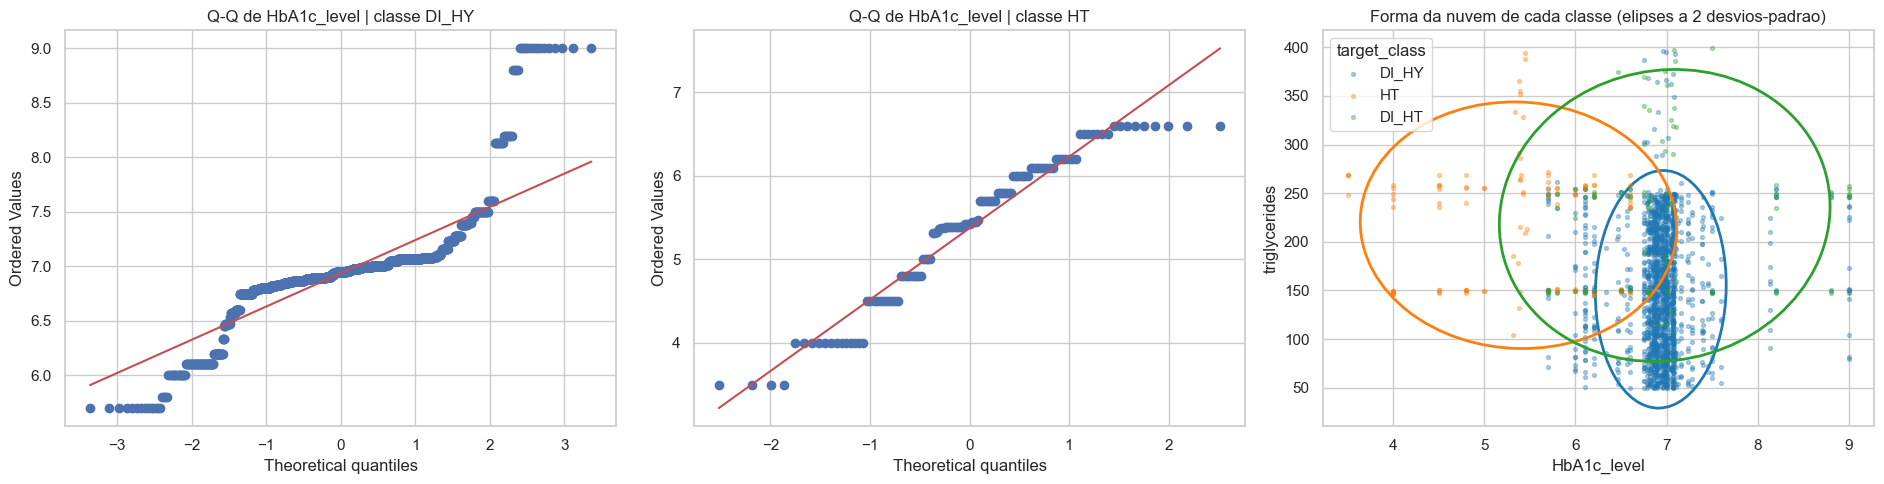

In [ ]:
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

def elipse_confianca(x, y, ax, n_std=2.0, **kwargs):
    """Desenha a elipse que representa a covariancia de (x, y)."""
    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    rx, ry = np.sqrt(1 + pearson), np.sqrt(1 - pearson)
    elipse = Ellipse((0, 0), width=rx*2, height=ry*2, facecolor='none', **kwargs)
    transf = (transforms.Affine2D()
              .rotate_deg(45)
              .scale(np.sqrt(cov[0, 0]) * n_std, np.sqrt(cov[1, 1]) * n_std)
              .translate(np.mean(x), np.mean(y)))
    elipse.set_transform(transf + ax.transData)
    return ax.add_patch(elipse)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Q-Q plots da feature mais discriminativa, uma por classe
for ax, k in zip(axes[:2], ['DI_HY', 'HT']):
    stats.probplot(df.loc[df[TARGET_CLS] == k, 'HbA1c_level'], dist='norm', plot=ax)
    ax.set_title(f'Q-Q de HbA1c_level | classe {k}')

# Forma da nuvem de pontos de cada classe (pressuposto de covariancia comum)
ax = axes[2]
cores = {'DI_HY': 'tab:blue', 'HT': 'tab:orange', 'DI_HT': 'tab:green'}
for k in classes:
    sub = df[df[TARGET_CLS] == k]
    ax.scatter(sub['HbA1c_level'], sub['triglycerides'], s=8, alpha=.35,
               color=cores[k], label=k)
    elipse_confianca(sub['HbA1c_level'].values, sub['triglycerides'].values, ax,
                     n_std=2, edgecolor=cores[k], lw=2)
ax.set_xlabel('HbA1c_level'); ax.set_ylabel('triglycerides')
ax.set_title('Forma da nuvem de cada classe (elipses a 2 desvios-padrao)')
ax.legend(title='target_class')
plt.tight_layout(); plt.show()

**Conclusões — e são a base da justificação a dar na Parte 3.**

**O pressuposto de normalidade não se verifica.** O teste de Shapiro-Wilk rejeita a normalidade em
praticamente todos os pares (*feature*, classe), com p-values muito abaixo de 0.05 — a única exceção é
`bmi` na classe `DI_HT`, que tem apenas 85 observações e, por isso, pouca potência para rejeitar. Os
gráficos Q-Q mostram desvios claros em relação à reta, sobretudo nas caudas.

**O pressuposto de covariância comum também é questionável.** O desvio-padrão de `HbA1c_level` é de
cerca de 0.36 na classe `DI_HY` mas de 0.91 em `DI_HT` — um rácio superior a 2.5. As elipses confirmam
visualmente: as nuvens das três classes não têm a mesma forma nem a mesma orientação, que é exatamente a
situação em que, segundo as aulas, uma matriz de covariância partilhada distorce a representação de
todas as classes.

**Como ler isto na escolha do método?** Os argumentos não apontam todos no mesmo sentido, e é essa
tensão que deve ser discutida:

- *A favor da Regressão Logística*: não assume normalidade nem covariâncias iguais, e nenhuma das duas
  condições se verifica aqui.
- *A favor da LDA*: nas aulas foi referido que a LDA é preferível quando há **mais de duas classes**
  (temos três) e quando a amostra é pequena — e as classes minoritárias têm, de facto, poucos registos
  (85 e 117). Foi também referido que, com classes bem separadas, as estimativas da Regressão Logística
  podem tornar-se instáveis; `HbA1c_level` separa `HT` de forma bastante nítida.
- *A favor de experimentar QDA*, se for permitido: é a resposta natural a covariâncias diferentes entre
  classes.

A violação dos pressupostos **não invalida** a aplicação da LDA — na prática ela é razoavelmente robusta,
sobretudo com n = 2000 — mas obriga a não justificar a escolha apenas pela teoria. A decisão final deve
assentar na comparação empírica dos dois métodos sob os vários esquemas de reamostragem, usando estas
observações como enquadramento.

### 3.9 Relação entre os dois targets e pairplot das features mais relevantes

Terminamos a análise bivariada com uma visão conjunta das *features* mais promissoras. O *pairplot*
mostra, de uma só vez, a distribuição de cada variável por classe (na diagonal) e todas as relações
duas a duas (fora da diagonal), com os pontos coloridos pela classe.

O objetivo é perceber se alguma **combinação** de *features* separa as classes melhor do que qualquer
uma delas isoladamente.

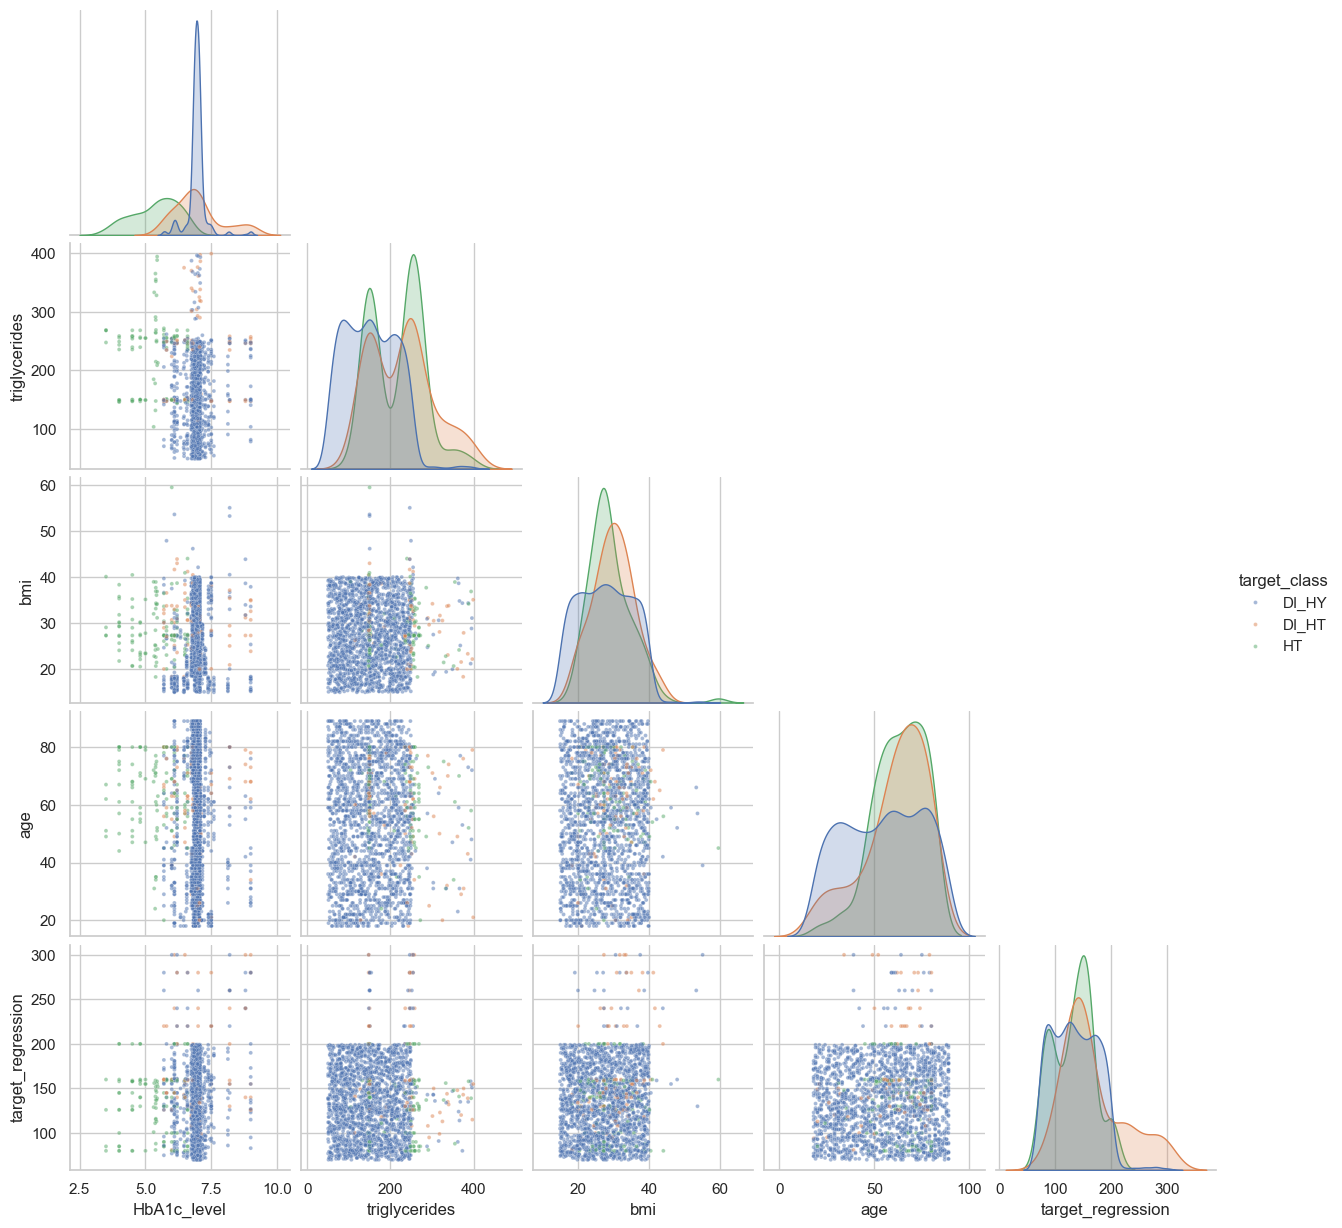

In [ ]:
key = ['HbA1c_level', 'triglycerides', 'bmi', 'age', TARGET_REG]
sns.pairplot(df[key + [TARGET_CLS]], hue=TARGET_CLS, corner=True,
             plot_kws={'s': 8, 'alpha': .5}, diag_kws={'common_norm': False})
plt.show()

**Conclusões:** O *pairplot* confirma e enriquece o que já sabíamos, a *feature* **`HbA1c_level` isola bem a classe
`HT`**, formando um grupo claramente deslocado para a esquerda, e a sua **combinação com
`triglycerides`** ajuda a separar `DI_HT` e `HT` de `DI_HY`.

Permanece, contudo, uma **sobreposição considerável entre `DI_HT` e `DI_HY`**. Nenhuma combinação das
*features* mais relevantes as distingue de forma nítida. É previsível que esta seja a
distinção mais difícil para os classificadores e a principal fonte de erro. Combinando isso com o
facto de `DI_HT` ter apenas 85 registos, é de se esperar que seja esta a classe com pior *recall*.

### 3.8 Artefacto detetado: precisão decimal dos valores depende da classe
Olhando para as linhas do dataset, alguns valores são números "redondos" (`hdl = 72.0`) e outros têm muitas casas decimais (`hdl = 64.3313679245283`), o que sugere que foram imputados ou gerados sinteticamente. Vamos verificar se isto está relacionado com a classe.

In [ ]:
def not_rounded(s):
    return ((s * 10).round(6) % 1 != 0)

frac = pd.DataFrame({c: df.groupby(TARGET_CLS)[c].apply(lambda s: not_rounded(s).mean())
                     for c in num_feats}).T[classes]
frac.sort_values('DI_HY')

target_class,DI_HY,HT,DI_HT
age,0.000,0.000,0.000
cholesterol,0.031,0.812,0.671
triglycerides,0.031,0.812,0.671
bmi,0.049,0.923,0.953
systolic_bp,0.053,1.000,0.941
ldl,0.056,1.000,1.000
sleep_hours,0.056,1.000,1.000
hdl,0.056,1.000,1.000
heart_rate,0.056,1.000,1.000
salt_intake,0.056,1.000,1.000


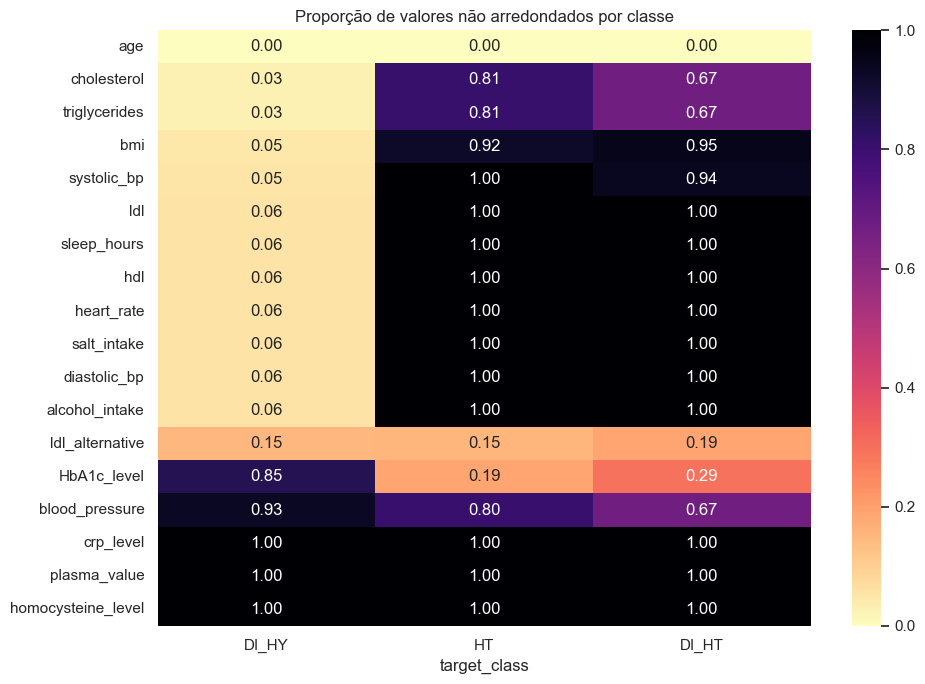

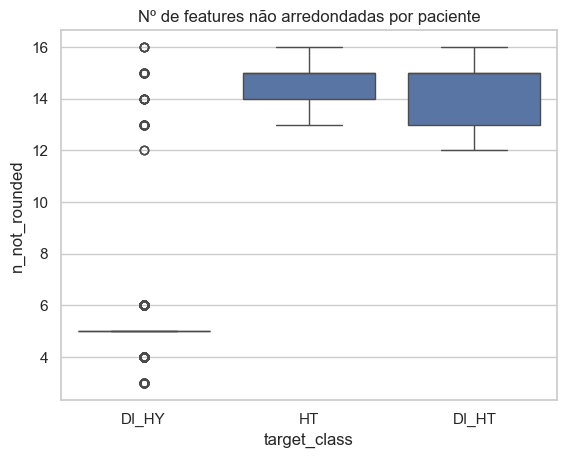

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(frac.sort_values('DI_HY'), annot=True, fmt='.2f', cmap='magma_r', ax=ax)
ax.set_title('Proporção de valores não arredondados por classe')
plt.tight_layout(); plt.show()

df_tmp = df.assign(n_not_rounded=sum(not_rounded(df[c]).astype(int) for c in num_feats))
sns.boxplot(data=df_tmp, x=TARGET_CLS, y='n_not_rounded', order=classes)
plt.title('Nº de features não arredondadas por paciente'); plt.show()

**Conclusões:**

Nas classes minoritárias (`HT` e `DI_HT`),
praticamente **100%** dos valores de `hdl`, `heart_rate`, `alcohol_intake`, `ldl`, `systolic_bp` e `bmi`
têm muitas casas decimais. Na classe maioritária `DI_HY`, apenas cerca de **5%** estão nessa situação.
Com `HbA1c_level` acontece exatamente o inverso.

Isto significa que os registos das classes minoritárias foram **gerados ou imputados por um processo
diferente** do usado na classe maioritária.

**Implicações, por ordem de importância:**

1. Um modelo flexível pode aprender a classe a partir da **"forma" do número** e não do seu valor clínico. Isto é *data leakage* e leva a um desempenho otimista que não generalizaria para dados reais.
2. Os modelos lineares pedidos (Regressão Logística e LDA) usam o valor e não a precisão decimal, por isso são pouco afetados. Mesmo assim, **não devemos criar features derivadas da precisão**, e a MI deve ser interpretada com cautela neste dataset.
3. Para avaliar relevância clínica usamos sobretudo os testes de Kruskal-Wallis/η², χ²/V de Cramér e as correlações.

## 4. Síntese e preparação para as fases seguintes

### 4.1 Quadro-resumo das features

Reunimos numa única tabela as medidas de associação calculadas ao longo da análise bivariada, para
sustentar com números as decisões que se seguem.

In [ ]:
summary = pd.DataFrame(index=num_feats + cat_cols)
summary['|r| target_reg'] = rel_reg['pearson'].abs()
summary['eta2 target_reg (cat)'] = cat_reg['eta2']
summary['eta2 target_class'] = num_cls['eta2']
summary['CramersV target_class'] = cat_cls['cramers_v']
summary['p target_class'] = num_cls['p_value'].combine_first(cat_cls['p_value'])
summary.sort_values('p target_class')

,|r| target_reg,eta2 target_reg (cat),eta2 target_class,CramersV target_class,p target_class
HbA1c_level,0.055,NaN,0.410,NaN,0.000
triglycerides,0.037,NaN,0.105,NaN,0.000
blood_pressure,0.015,NaN,0.009,NaN,0.000
age_level,NaN,0.005,NaN,0.113,0.000
bmi_level,NaN,0.003,NaN,0.108,0.000
low_hdl_cholesterol,NaN,0.001,NaN,0.125,0.000
age,0.054,NaN,0.013,NaN,0.000
homocysteine_level,0.016,NaN,0.004,NaN,0.000
physical_activity,NaN,0.003,NaN,0.070,0.001
bmi,0.070,NaN,0.006,NaN,0.003


### 4.2 Features constantes, redundantes e pouco informativas

| Tipo | Feature(s) | Justificação (com evidência) | Ação proposta |
|---|---|---|---|
| **Constante** | `calcium_baseline` | Valor único (9.42) em 2000 registos; desvio-padrão exatamente 0 (secção 1.3) | **Remover** |
| **Redundante** | `systolic_index` | Idêntica a `systolic_bp` em todas as 2000 linhas. Com ambas presentes, o número de condição atinge 1e+17 | **Remover**, manter `systolic_bp` |
| **Redundante** | `age_normalized` | Reescala determinística de `age`: (age − 2)/87, resíduo máximo 1e-06 | **Remover**, manter `age` |
| **Parcialmente redundante** | `age_level`, `bmi_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol` | Discretizações de `age`, `bmi`, `hdl`, `ldl`. As duas *flags* não correspondem aos limiares clínicos habituais | Preferir a variável contínua; **testar na seleção de *features*** |
| **Suspeita** | `ldl_alternative` | Mesmos valores de `ldl` mas permutados: coincide em 18 de 2000 linhas, r ≈ −0.005. Distribuição correta, valor desligado do paciente | **Tratar com cautela**; avaliar com Lasso |
| **Pouco informativas** | `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake`, `salt_intake`, `sleep_hours`, `cholesterol`, `plasma_value`, `crp_level`; e as categóricas `gender` e `stress_level` | Distribuições idênticas entre classes (Kruskal-Wallis não significativo, η² ≈ 0) ou sem associação (V de Cramér, p > 0.2 ); correlação ≈ 0 com `target_regression`. | **Candidatas a eliminação**; confirmar com Lasso na Parte 4 |
| **Informativas** | `HbA1c_level`, `triglycerides`, `bmi`/`bmi_level`, `age`/`age_level` | Diferenças claras entre classes: η² = 0.41 e 0.105 nas duas primeiras, com p ≈ 2e-67 e 8e-38 | **Manter** |

### 4.3 Conclusões gerais da EDA

1. **Qualidade dos dados.** Não há valores em falta nem registos duplicados. Existem *outliers* pela
   regra do IQR, mas resultam da forma concentrada de algumas distribuições e são informativos — não
   foram removidos.
2. **Desequilíbrio severo.** `target_class` tem 89.9% dos registos numa única classe. Obriga a
   estratificação e a métricas robustas; a *accuracy* isolada seria enganadora.
3. **Regressão: sinal muito fraco.** Nenhuma *feature* numérica atinge |r| = 0.07 com
   `target_regression`, e nem Spearman nem a informação mútua revelam relações não lineares escondidas.
   É de esperar R² baixo. Detetou-se ainda acumulação de observações nos extremos (70 e 300),
   compatível com truncatura.
4. **Classificação: sinal claro, mas concentrado.** `HbA1c_level` (η² = 0.41) e `triglycerides`
   (η² = 0.105) separam as classes de forma estatisticamente forte; apenas **6 das 18** *features*
   numéricas do conjunto de trabalho têm efeito significativo.
5. **Sem multicolinearidade.** Removidas as redundâncias, todos os VIF ficam abaixo de 1.05.
6. **Artefacto de precisão decimal.** A forma dos números depende da classe, o que constitui potencial
   *leakage* e invalida a informação mútua como critério de seleção neste dataset.
7. **Fortes indícios de dados sintéticos**: distribuições uniformes, correlações nulas entre variáveis
   clinicamente relacionadas e o artefacto de 3.11.

### 4.4 Implicações para a Parte 2 — Regressão

- O **modelo linear simples** deverá usar o melhor preditor individual, que pela análise de 3.5 é `bmi`
  (|r| ≈ 0.070), seguido de `salt_intake` e `HbA1c_level`. Deve testar-se mais do que um e comparar.
- Na **regressão múltipla**, a ausência de colinearidade (3.3) significa que os coeficientes serão
  estáveis e interpretáveis, ainda que pequenos.
- Esperam-se **R² próximos de zero**. A discussão deve centrar-se em porquê — ausência de sinal nas
  *features*, possível truncatura do alvo — e não em tentar inflacionar a métrica.
- Avaliação com **R², MAE e RMSE**, como pedido, sobre um *holdout* fixado com semente 42.

### 4.5 Implicações para a Parte 3 — Classificação

- **Métricas**: F1 macro, *balanced accuracy*, *recall* por classe e matriz de confusão. A *accuracy*
  deve ser reportada, mas como métrica secundária, dado o *baseline* trivial de 89.9%.
- **Reamostragem estratificada** em todos os esquemas (*holdout*, k = 5, k = 10), para garantir que as
  85 observações de `DI_HT` estão representadas em cada *fold*.
- **LOOCV** é viável (2000 ajustes) mas computacionalmente pesado; convém medir o tempo. Espera-se que
  produza estimativas com **variância mais elevada** do que a validação cruzada em k *folds*, conforme
  discutido nas aulas.
- **LDA vs Regressão Logística**: os pressupostos da LDA não se verificam plenamente (3.9), mas o
  problema tem três classes e duas delas são pequenas, o que joga a favor da LDA. A escolha deve ser
  justificada combinando esta análise com os resultados empíricos.
- Prever que a classe **`DI_HT` terá o pior *recall***, pela sobreposição com `DI_HY` observada em 3.10.